In [1]:
# copyright ################################# #
# This file is part of the wakis Package.     #
# Copyright (c) CERN, 2026.                   #
# ########################################### #

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eshipton/Wakis/blob/main/tutorials/04_radiation_and_antennas/04-09_implant_antennas_tissue/implant_antennas_tissue.ipynb)

# Tutorial 4.9 · Electric vs Magnetic Implant Antennas in Lossy Biological Tissue

In free space ([Tutorial 4.1](../04-01_point_dipole/point_dipole.ipynb)), an electrically small electric dipole ($\mathrm{TM}_{10}$) and an electrically small magnetic dipole or current loop ($\mathrm{TE}_{10}$) are dual radiators: both store reactive power in a $1/r^3$ quasi-static near field ($kr \ll 1$) and launch the same $\sin^2\theta$ far-field radiation pattern ($D_0 = 1.5$). Once the antenna is encapsulated inside a millimeter-scale biocompatible housing of radius $a$ and implanted in **lossy biological tissue** (such as human muscle, $\tilde{\varepsilon}_r(\omega) = \varepsilon_r'(\omega) - j\varepsilon_r''(\omega) = \varepsilon_r'(\omega) - j\sigma_{\mathrm{eff}}(\omega)/(\omega\varepsilon_0)$, whereas $\mu_r = 1$), electromagnetic duality is broken by the medium itself: **biological tissue is strongly conducting and dielectric ($\varepsilon_r' \sim 50\text{–}60, \sigma_{\mathrm{eff}} \sim 0.8\text{–}1.7\;\mathrm{S/m}$), but non-magnetic ($\mu'' = 0$)**.

A widespread rule of thumb states that *"magnetic antennas lose less power in tissue than electric antennas."* In reality, that statement holds **only under specific physical conditions** on the electrical capsule radius $|k_{\mathrm{m}}|a$, the operating frequency $f$, the antenna's feed-gap electric field, the capsule permittivity $\varepsilon_{\mathrm{cap}}$, and the source-to-capsule radius ratio $r/a$:

1. **Part 1 — Near-Zone Ohmic Dissipation ($\propto 1/(|k_{\mathrm{m}}|a)^2$, derived here):** Outside an insulating capsule of radius $a$ in a homogeneous medium of complex wavenumber $k_{\mathrm{m}} = \beta - j\alpha$, an ideal electric dipole ($\mathrm{TM}_{10}$) excites a quasi-static electric field $|\mathbf{E}_{\mathrm{TM}}| \propto r^{-3}$ that drives intense local Joule heating $\frac{1}{2}\sigma_{\mathrm{eff}}\int_a^\infty |\mathbf{E}|^2\,\mathrm{d}V \propto (\alpha / |k_{\mathrm{m}}|^4 a^3)$. By contrast, an ideal magnetic dipole ($\mathrm{TE}_{10}$) stores its $r^{-3}$ energy in the **magnetic** field $|\mathbf{H}_{\mathrm{TE}}| \propto r^{-3}$ (which suffers zero magnetic loss in non-magnetic tissue, $\mu'' = 0$), while its Faraday-induced electric field scales only as $|\mathbf{E}_{\mathrm{TE}}| \propto \omega\mu_0 m / r^2$, producing a near-zone dissipation integral $\propto (\alpha / |k_{\mathrm{m}}|^2 a)$. Removing the arbitrary outer-radius propagation factor $\exp(-2\alpha(b-a))$ from Zhou & Pan's path ratio $S(b)/S(a)$ [1] defines the **$b$-independent near-zone excess loss ratio** $\mathcal{R}_{\mathrm{NZ}}(a) \equiv \Delta_{\mathrm{TM}}(a) / \Delta_{\mathrm{TE}}(a) = 1 + 2\alpha/(|k_{\mathrm{m}}|^2 a) + 1/(|k_{\mathrm{m}}|a)^2 \sim 1/(|k_{\mathrm{m}}|a)^2$.
2. **Part 2 — Dispersive Muscle Pole Fitting, 3D FIT Power Bookkeeping & Capsule-Interface Correction (derived here):** Using `wakis.dispersive.fit_poles`, we fit a passive 3-pole Debye model to the 4-pole Cole–Cole muscle spectrum of Gabriel, Lau & Gabriel (1996) [2] across the $403\;\mathrm{MHz}$ MedRadio and $2.45\;\mathrm{GHz}$ ISM bands ($0.20\%$ RMS fit error). In 3D FIT (`SolverFIT3D`), we verify discrete Poynting closure $P_{\mathrm{in}}(r_1) - P_{\mathrm{out}}(r_2) = \int_{r_1}^{r_2}\sigma_{\mathrm{eff}}(\omega,\Delta t)|\mathbf{E}|^2\,\mathrm{d}V$ to $\le 0.76\%$ ($0.55\%$ for $\mathrm{TM}$ at $403\;\mathrm{MHz}$, $0.35\%$ at $2.45\;\mathrm{GHz}$), match the cubic-surface Zhou–Pan exterior shell loss ratio $(P_1-P_2)/P_2$ within $2.0\text{–}7.5\%$ at $403\;\mathrm{MHz}$ and $0.4\text{–}3.6\%$ at $2.45\;\mathrm{GHz}$, and compare the spherical **capsule-interface reaction factor** $|C_{\mathrm{TM}}^{\mathrm{full}}(a)|^2$ ($1.426$ full-wave vs $2.210$ quasi-static at $2.45\;\mathrm{GHz}$ in air; 3D FIT gives $1.796$ on the uniform $\Delta x = 0.64\;\mathrm{mm}$ grid and $1.683$ on the $\Delta x_{\min} = 0.35\;\mathrm{mm}$ graded mesh, $25.96\%$ and $18.04\%$ above full-wave point-dipole theory, and $2.80\text{–}3.08$ vs $2.16\text{–}2.20$ at $403\;\mathrm{MHz}$) against $|C_{\mathrm{TE}}(a)|^2 = 0.9952$ vs $1.0000$ ($0.48\%$).
3. **Part 3 — Realistic Gapped Wire Feeds & SAR Hotspots:** A real wire loop is driven across a finite feed gap where the impressed voltage concentrates a local quasi-static electric field. On a locally refined graded mesh ($\Delta x_{\min} = 0.35\;\mathrm{mm}$, $4.0$ cells across the $1.40\;\mathrm{mm}$ wire and feed gap inside an $a = 2.25\;\mathrm{mm}$ capsule), an ideal 4-segment loop achieves near-zone efficiency $\eta_{\mathrm{NZ}} = 54.19\%$ at $403\;\mathrm{MHz}$ ($54.21\%$ in a ceramic control $\varepsilon_{\mathrm{cap}} = 12$). Because the feed gap at $r_{\mathrm{ant}} = 1.40\;\mathrm{mm}$ is buffered from the $a = 2.25\;\mathrm{mm}$ wall, the single-gap PEC wire loop's global near-zone efficiency drops by only $1.02\%$ in loss/out ($\eta_{\mathrm{NZ}} = 53.94\%$), yet the gap $\mathbf{E}$-field hotspot breaks hemisphere symmetry ($53.24\%$ of loss in $x > 0$ vs $49.99\%$) and increases **peak local tissue SAR by $8.6\times$** ($257.1$ vs $29.8\;\mathrm{W/kg/mW}$, compared with $4372.7\;\mathrm{W/kg/mW}$ and $\eta_{\mathrm{NZ}} = 13.23\%$ for the gapped dipole).
4. **Part 4 — Fundamental Efficiency Bounds (Liška *et al.* 2024; Soares *et al.* 2023) & 3D FIT Size Sweep:** In a $61.5\;\mathrm{mm}$ muscle phantom with capsule radius $a = 7.5\;\mathrm{mm}$ and $\sigma_{\mathrm{Cu}} = 5.56\times 10^7\;\mathrm{S/m}$ [3], below $r/a = 0.32$ the bound-achieving current is $\mathrm{TM}_{1m}$-like and its loss is tissue-dominated ($\delta_{\mathrm{tis}} > \delta_{\mathrm{ant}}$). $\mathrm{TE}_{1m}$-like currents couple less to tissue, but small ones act like a short circuit (low radiation resistance, high ohmic $\delta_{\mathrm{ant}}$), so $\mathrm{TE}$ becomes optimal only for $r/a > 0.32$ [3, Sec. III], whereas at $2.45\;\mathrm{GHz}$ the bound is nearly flat ($\approx -25.1 \to -24.8\;\mathrm{dB}$). In our resolved 3D FIT $r/a \in \{0.25, 0.50, 0.75\}$ sweep ($a = 2.80\;\mathrm{mm}, \Delta x_{\min} = 0.35\;\mathrm{mm}$, $\ge 4$ cells across every loop diameter, $2.24\;\mathrm{mm}$ CPML clearance), the ideal loop near-zone efficiency across $[3.57, 5.79]\;\mathrm{mm}$ is $\eta_{\mathrm{NZ}} = 58.49\%, 58.34\%, 57.97\%$ at $403\;\mathrm{MHz}$ (vs $25.92\%$ for the $r/a = 0.50$ $\mathrm{TM}$ dipole), while including single-turn copper wire resistance ($r_{\mathrm{wire}} = 0.08\;\mathrm{mm}$ ($0.16\;\mathrm{mm}$ diameter, $\approx\text{AWG }34$), $\sigma_{\mathrm{Cu}} = 5.8\times 10^7\;\mathrm{S/m}$, normalized by the DFT-monitored loop current) gives total near-zone efficiency $\eta_{\mathrm{tot}} = 0.44\%, 3.33\%, 9.91\%$ with $P_{\mathrm{Cu}}/P_{\mathrm{out}} = 226.4, 28.28, 8.36$ ($8.37$ from rounded $\eta$; ratios $8.0 = 2^3$ and $3.38 = 1.5^3$, confirming $\delta_{\mathrm{ant}}^{\mathrm{TE}} \propto r^{-3}$ at fixed wire radius).
5. **Part 5 — Causal Lorentz Model Ferrite Core:** Loading the loop ($r_{\mathrm{wire}} = 0.06\;\mathrm{mm}$ ($0.12\;\mathrm{mm}$ diameter, $\approx\text{AWG }36\text{–}37$)) with a model NiZn ferrite core ($\mu_s = 7.5, f_{\mathrm{FMR}} = 1.15\;\mathrm{GHz}$, single-pole Lorentz $Q = 46$, which is narrower than real NiZn spectra and underestimates $\mu_r''$ at $403\;\mathrm{MHz}$) yields $\mu_r(403\;\mathrm{MHz}) = 8.41 - 0.064j$ and boosts total near-zone efficiency (on an $N = 34^3$ domain where $r_2 = 5.76\;\mathrm{mm}$ sits $3$ cells [$2.16\;\mathrm{mm}$] short of the CPML inner face) by **$4.42\times$ at $403\;\mathrm{MHz}$** ($\eta_{\mathrm{tot}}: 3.35\% \to 14.82\%$). At $2.45\;\mathrm{GHz}$ ($\mu_r(2.45\;\mathrm{GHz}) = -0.84 - 0.024j$), although $P_{\mathrm{out}}$ per unit current rises $2.03\times$, core dissipation ($P_{\mathrm{core}} = 8.84\times 10^{-4}\;\mathrm{W}$) near the magnetostatic surface-mode condition ($\mu_r' \approx -1$, here $\mu_r' = -0.84$) excited by the winding on the core face reduces $\eta_{\mathrm{tot}}$ to **$0.25\times$** ($\eta_{\mathrm{tot}}: 58.04\% \to 14.65\%$).

---

## Learning Goals

1. **Derive** from the spherical-wave solutions in a lossy medium ($k_{\mathrm{m}} = \beta - j\alpha$) the radial Poynting fluxes $S_{\mathrm{TM}}(r)$ and $S_{\mathrm{TE}}(r)$ of Zhou & Pan (2023) [1], prove the differential Poynting identity $-\mathrm{d}S/\mathrm{d}r = \frac{1}{2}\sigma_{\mathrm{eff}}\oint |\mathbf{E}|^2 r^2\mathrm{d}\Omega$, and formulate the **$b$-independent near-zone excess loss ratio** $\mathcal{R}_{\mathrm{NZ}}(a) = \Delta_{\mathrm{TM}}(a)/\Delta_{\mathrm{TE}}(a) \sim 1/(|k_{\mathrm{m}}|a)^2$ (derived here).
2. **Fit** the Gabriel, Lau & Gabriel (1996) [2] 4-pole Cole–Cole permittivity of human muscle to a causal 3-pole Debye model via `wakis.dispersive.fit_poles`, and verify discrete 3D FIT Poynting conservation across concentric `FluxMonitor` and `DFTMonitor` shells.
3. **Derive and test** the quasi-static and full-wave spherical **capsule-interface reaction factor** $C_{\mathrm{TM}}(a)$ and $C_{\mathrm{TE}}(a)$ (derived here), explaining why an air or ceramic capsule modifies the exterior field of a fixed-moment electric dipole by $|3\tilde{\varepsilon}_{\mathrm{m}}/(2\tilde{\varepsilon}_{\mathrm{m}} + \varepsilon_{\mathrm{cap}})|^2$ while leaving a magnetic loop's quasi-static exterior flux unchanged ($|C_{\mathrm{TE}}^{\mathrm{QS}}|^2 = 1$).
4. **Quantify** feed-gap electric-field contamination and Specific Absorption Rate ($\mathrm{SAR} = \sigma_{\mathrm{eff}}|\mathbf{E}|^2 / \rho_{\mathrm{m}}$) in realistic gapped wire loops versus ideal magnetic loops and gapped electric dipoles across frequency ($403\;\mathrm{MHz}$ vs $2.45\;\mathrm{GHz}$) and capsule permittivity ($\varepsilon_{\mathrm{cap}} \in \{1, 12\}$).
5. **Compare** 3D FIT implant efficiencies against the fundamental spherical-mode bounds of Liška *et al.* (2024) [3] ($\mathrm{TM}_{1m}\to\mathrm{TE}_{1m}$ switch at $r/a = 0.32$ at $403\;\mathrm{MHz}$) and the optimal frequency/depth trends of Soares *et al.* (2023) Table II [4], and evaluate when a causal Lorentz magnetic core (`wakis.dispersive.Lorentz`) improves or degrades loop efficiency.

---

## Theory & Step-by-Step Derivations

### 1. Why a Small Source in a Lossy Medium Loses Power in Its Near Zone (Derived Here)

Consider a homogeneous, isotropic, non-magnetic ($\mu = \mu_0$) lossy medium characterized at angular frequency $\omega = 2\pi f$ ($\mathrm{e}^{+j\omega t}$ time convention) by complex permittivity and complex wavenumber

$$
\tilde{\varepsilon}(\omega) = \varepsilon_0\,\tilde{\varepsilon}_r(\omega) = \varepsilon_0\bigl[\varepsilon_r'(\omega) - j\varepsilon_r''(\omega)\bigr] = \varepsilon_0\varepsilon_r'(\omega) - j\frac{\sigma_{\mathrm{eff}}(\omega)}{\omega}, \qquad k_{\mathrm{m}} = \omega\sqrt{\mu_0\tilde{\varepsilon}(\omega)} = \beta - j\alpha, \quad (\beta > 0, \;\alpha \ge 0).
$$

Squaring $k_{\mathrm{m}} = \beta - j\alpha$ yields the exact relations between $(\beta, \alpha)$ and $(\varepsilon_r', \sigma_{\mathrm{eff}})$:

$$
\beta^2 - \alpha^2 = \omega^2\mu_0\varepsilon_0\varepsilon_r', \qquad 2\beta\alpha = \omega\mu_0\sigma_{\mathrm{eff}}, \qquad |k_{\mathrm{m}}|^2 = \beta^2 + \alpha^2.
$$

#### 1.1 Exact spherical-wave fields of $\mathrm{TM}_{10}$ (electric) and $\mathrm{TE}_{10}$ (magnetic) point dipoles

An ideal $z$-directed electric current element of moment $p_I = I_e\,\mathrm{d}l$ ($\mathrm{A\cdot m}$) at the origin generates the fundamental $\mathrm{TM}_{10}$ spherical wave ($E_r, E_\theta, H_\phi$):

$$
\begin{aligned}
H_\phi^{\mathrm{TM}}(r, \theta) &= \frac{I_e\,\mathrm{d}l}{4\pi}\,k_{\mathrm{m}}^2\sin\theta\left(\frac{j}{k_{\mathrm{m}} r} + \frac{1}{(k_{\mathrm{m}} r)^2}\right)\mathrm{e}^{-j k_{\mathrm{m}} r}, \\
E_r^{\mathrm{TM}}(r, \theta) &= \frac{I_e\,\mathrm{d}l}{2\pi}\,\frac{\omega\mu_0}{k_{\mathrm{m}}}\,k_{\mathrm{m}}^2\cos\theta\left(\frac{1}{(k_{\mathrm{m}} r)^2} - \frac{j}{(k_{\mathrm{m}} r)^3}\right)\mathrm{e}^{-j k_{\mathrm{m}} r}, \\
E_\theta^{\mathrm{TM}}(r, \theta) &= \frac{I_e\,\mathrm{d}l}{4\pi}\,\frac{\omega\mu_0}{k_{\mathrm{m}}}\,k_{\mathrm{m}}^2\sin\theta\left(\frac{j}{k_{\mathrm{m}} r} + \frac{1}{(k_{\mathrm{m}} r)^2} - \frac{j}{(k_{\mathrm{m}} r)^3}\right)\mathrm{e}^{-j k_{\mathrm{m}} r}.
\end{aligned}
$$

By electromagnetic duality ($I_e\,\mathrm{d}l \to I_m\,\mathrm{d}l = j\omega\mu_0 m$ where $m = I_{\mathrm{loop}} A$ is the magnetic dipole moment in $\mathrm{A\cdot m^2}$, $\mathbf{E} \to \mathbf{H}$, $\mathbf{H} \to -\mathbf{E}$, and $\tilde{\varepsilon} \leftrightarrow \mu_0$), a small current loop in the $xy$-plane generates the fundamental $\mathrm{TE}_{10}$ spherical wave ($H_r, H_\theta, E_\phi$):

$$
\begin{aligned}
E_\phi^{\mathrm{TE}}(r, \theta) &= -\frac{I_m\,\mathrm{d}l}{4\pi}\,k_{\mathrm{m}}^2\sin\theta\left(\frac{j}{k_{\mathrm{m}} r} + \frac{1}{(k_{\mathrm{m}} r)^2}\right)\mathrm{e}^{-j k_{\mathrm{m}} r}, \\
H_r^{\mathrm{TE}}(r, \theta) &= \frac{I_m\,\mathrm{d}l}{2\pi}\,\frac{k_{\mathrm{m}}}{\omega\mu_0}\,k_{\mathrm{m}}^2\cos\theta\left(\frac{1}{(k_{\mathrm{m}} r)^2} - \frac{j}{(k_{\mathrm{m}} r)^3}\right)\mathrm{e}^{-j k_{\mathrm{m}} r}, \\
H_\theta^{\mathrm{TE}}(r, \theta) &= \frac{I_m\,\mathrm{d}l}{4\pi}\,\frac{k_{\mathrm{m}}}{\omega\mu_0}\,k_{\mathrm{m}}^2\sin\theta\left(\frac{j}{k_{\mathrm{m}} r} + \frac{1}{(k_{\mathrm{m}} r)^2} - \frac{j}{(k_{\mathrm{m}} r)^3}\right)\mathrm{e}^{-j k_{\mathrm{m}} r}.
\end{aligned}
$$

Look at the radial scaling of the electric field in the near zone ($|k_{\mathrm{m}}|r \ll 1$):
- **Electric dipole ($\mathrm{TM}_{10}$):** Both $E_r^{\mathrm{TM}}$ and $E_\theta^{\mathrm{TM}}$ contain a **$1/(k_{\mathrm{m}} r)^3$ quasi-static Coulomb/conduction field**, so $|\mathbf{E}_{\mathrm{TM}}(r)|^2 \propto r^{-6}$ as $r \to 0$.
- **Magnetic loop ($\mathrm{TE}_{10}$):** The $1/(k_{\mathrm{m}} r)^3$ singularity sits purely in the magnetic components $(H_r^{\mathrm{TE}}, H_\theta^{\mathrm{TE}})$, which experience **zero magnetic dissipation** ($\mu'' = 0$). The Faraday-induced electric field $E_\phi^{\mathrm{TE}}$ has **no $1/r^3$ term**—its leading near-zone behavior is $E_\phi^{\mathrm{TE}} \propto 1/r^2$, so $|\mathbf{E}_{\mathrm{TE}}(r)|^2 \propto r^{-4}$ as $r \to 0$.

#### 1.2 Radial Poynting flux $S(r)$ and reproduction of Zhou & Pan (2023) Eqs. (19)–(20) & (30) (Derived Here)

Integrating the time-averaged radial Poynting vector $\langle S_r \rangle = \frac{1}{2}\operatorname{Re}(\mathbf{E}\times\mathbf{H}^*)\cdot\hat{\mathbf{r}}$ over a sphere of radius $r$ ($\int_0^\pi \sin^3\theta\,\mathrm{d}\theta = 4/3$, $2\pi r^2 \cdot \frac{4}{3} = \frac{8\pi}{3}r^2$) gives:
- For the **magnetic dipole ($\mathrm{TE}_{10}$)**, $\langle S_r^{\mathrm{TE}}\rangle = -\frac{1}{2}\operatorname{Re}\bigl(E_\phi^{\mathrm{TE}} H_\theta^{\mathrm{TE}*}\bigr)$. Substituting $u = k_{\mathrm{m}} r = (\beta - j\alpha)r$ and $|\mathrm{e}^{-j k_{\mathrm{m}} r}|^2 = \mathrm{e}^{-2\alpha r}$:

$$
\operatorname{Re}\!\left[k_{\mathrm{m}}^*\left(\frac{j}{u} + \frac{1}{u^2}\right)\left(-\frac{j}{u^*} + \frac{1}{u^{*2}} + \frac{j}{u^{*3}}\right)\right] = \frac{\beta}{|k_{\mathrm{m}}|^2 r^2}\left[1 + \frac{2\alpha}{|k_{\mathrm{m}}|^2 r}\right],
$$

because the $r^{-5}$ cross-term $\operatorname{Re}(j k_{\mathrm{m}}^* / (|k_{\mathrm{m}}|^4 r^5)) = -\alpha / (|k_{\mathrm{m}}|^4 r^5)$ and the product $\operatorname{Re}((1/u^2)(j/u^{*3})) = +\alpha / (|k_{\mathrm{m}}|^4 r^5)$ cancel identically! This yields **Zhou & Pan (2023) Eq. (20)** [1]:

$$
\boxed{S_{\mathrm{TE}}(r) = \frac{1}{12\pi}(I_m\,\mathrm{d}l\,|k_{\mathrm{m}}|)^2\,\frac{c_0}{\eta_0\omega}\,\mathrm{e}^{-2\alpha r}\beta\left[1 + \frac{2\alpha}{|k_{\mathrm{m}}|^2 r}\right].}
$$

- For the **electric dipole ($\mathrm{TM}_{10}$)**, $\langle S_r^{\mathrm{TM}}\rangle = \frac{1}{2}\operatorname{Re}\bigl(E_\theta^{\mathrm{TM}} H_\phi^{\mathrm{TM}*}\bigr)$. Expanding the product with $1/k_{\mathrm{m}} = (\beta + j\alpha)/|k_{\mathrm{m}}|^2$ retains both the $r^{-2}$ and $r^{-3}$ near-zone brackets, yielding **Zhou & Pan (2023) Eq. (19)** [1]:

$$
\boxed{S_{\mathrm{TM}}(r) = \frac{1}{12\pi}(I_e\,\mathrm{d}l)^2\,\frac{\eta_0\omega}{c_0}\,\mathrm{e}^{-2\alpha r}\beta\left[1 + \frac{2\alpha}{|k_{\mathrm{m}}|^2 r} + \frac{1}{|k_{\mathrm{m}}|^2 r^2} - \frac{\beta^2 - 3\alpha^2}{|k_{\mathrm{m}}|^4 r^2} + \frac{2\alpha}{|k_{\mathrm{m}}|^4 r^3}\right],}
$$

where combining the two $1/r^2$ terms over a common denominator $|k_{\mathrm{m}}|^4 = \beta^2 + \alpha^2$ simplifies the bracket cleanly to

$$
1 + \Delta_{\mathrm{TM}}(r) = 1 + \frac{2\alpha}{|k_{\mathrm{m}}|^2 r} + \frac{4\alpha^2}{|k_{\mathrm{m}}|^4 r^2} + \frac{2\alpha}{|k_{\mathrm{m}}|^4 r^3}.
$$

Differentiating $S_{\mathrm{TM}}(r)$ and $S_{\mathrm{TE}}(r)$ with respect to $r$ and using $2\beta\alpha = \omega\mu_0\sigma_{\mathrm{eff}}$ confirms the exact differential Poynting identity at every radius $r > 0$:

$$
-\frac{\mathrm{d}S_{\mathrm{X}}(r)}{\mathrm{d}r} = \frac{1}{2}\sigma_{\mathrm{eff}}\oint_{|\mathbf{r}|=r} |\mathbf{E}_{\mathrm{X}}(r,\theta)|^2\,r^2\sin\theta\,\mathrm{d}\theta\,\mathrm{d}\phi, \qquad \mathrm{X}\in\{\mathrm{TM},\mathrm{TE}\}.
$$

#### 1.3 Zhou & Pan's path ratio vs our $b$-independent near-zone excess loss ratio (Derived Here)

For a dipole enclosed in a lossless insulating sphere of radius $a$ and observed at an outer sphere $b > a$, no power is dissipated inside $r < a$, so $P_{\mathrm{in}} = S_{\mathrm{X}}(a)$. Zhou & Pan [1] defined the two-radius ratio $\eta_{\mathrm{ZP,X}}(a, b) \equiv S_{\mathrm{X}}(b) / S_{\mathrm{X}}(a)$, whose TE-to-TM ratio in the electrically small limit $|k_{\mathrm{m}}|a \ll 1 \ll |k_{\mathrm{m}}|b$ reduces to **Zhou & Pan Eq. (30)**:

$$
\frac{\eta_{\mathrm{ZP,TE}}(a, b)}{\eta_{\mathrm{ZP,TM}}(a, b)} = \frac{1 + \Delta_{\mathrm{TM}}(a)}{1 + \Delta_{\mathrm{TE}}(a)}\cdot\frac{1 + \Delta_{\mathrm{TE}}(b)}{1 + \Delta_{\mathrm{TM}}(b)} \xrightarrow{|k_{\mathrm{m}}|a \ll 1 \ll |k_{\mathrm{m}}|b} \frac{2\alpha / (|k_{\mathrm{m}}|^4 a^3)}{2\alpha / (|k_{\mathrm{m}}|^2 a)} = \frac{1}{(|k_{\mathrm{m}}|a)^2}.
$$

Because $\eta_{\mathrm{ZP,X}}(a, b)$ mixes intrinsic near-zone dissipation with the arbitrary far-zone beer-Lambert path loss $\mathrm{e}^{-2\alpha(b - a)}$, we factor $S_{\mathrm{X}}(a) = S_{\mathrm{X,far}}(0)\,\mathrm{e}^{-2\alpha a}\,[1 + \Delta_{\mathrm{X}}(a)]$ and define two **$b$-independent near-zone metrics** (derived here):

$$
\boxed{\mathcal{R}_{\mathrm{NZ}}(a) \equiv \frac{\Delta_{\mathrm{TM}}(a)}{\Delta_{\mathrm{TE}}(a)} = 1 + \frac{2\alpha}{|k_{\mathrm{m}}|^2 a} + \frac{1}{(|k_{\mathrm{m}}|a)^2}, \qquad \frac{\eta_{\mathrm{NZ,TE}}(a)}{\eta_{\mathrm{NZ,TM}}(a)} \equiv \frac{1 + \Delta_{\mathrm{TM}}(a)}{1 + \Delta_{\mathrm{TE}}(a)}.}
$$

> **Note on Zhou & Pan (2023) seawater numerical example:** In Section III of Zhou & Pan [1] ($f = 1\;\mathrm{kHz}$ in seawater, $\varepsilon_r = 80, \sigma = 4\;\mathrm{S/m}, a = 0.3\;\mathrm{m}, b = 100\;\mathrm{m}$), exact evaluation of Eqs. (19)–(20) gives $|k_{\mathrm{m}}| = 0.17772\;\mathrm{m}^{-1}$, $|k_{\mathrm{m}}|a = 0.053315$, $t_1 = 2\alpha/(|k_{\mathrm{m}}|^2 a) = 26.526$, $t_{2a} = 1/(|k_{\mathrm{m}}|a)^2 = 351.810$, $t_{2b} = -(\beta^2-3\alpha^2)/(|k_{\mathrm{m}}|^4 a^2) = 351.809$, $t_3 = 2\alpha/(|k_{\mathrm{m}}|^4 a^3) = 9332.04$, yielding $\eta_{\mathrm{ZP,TM}} = 1.4155\times 10^{-15}$, $\eta_{\mathrm{ZP,TE}} = 5.1434\times 10^{-13}$, a full ratio of **$363.37$**, and a leading asymptote $1/(|k_{\mathrm{m}}|a)^2 = \mathbf{351.81}$. As documented in our literature review, the authors' printed numerical evaluation in their text/table does not match their own closed-form Eqs. (19)–(20); we therefore benchmark strictly against the exact closed-form analytical expressions and full-wave 3D FIT simulations.

---

### 2. Capsule-Interface Reaction Correction: Why the Capsule Wall Modifies $P_{\mathrm{out}}$ (Derived Here)

Zhou & Pan's analytical integration [1] evaluates the homogeneous-medium fields at $r = a$ without enforcing the dielectric boundary conditions across the physical interface at $r = a$ between the insulating capsule ($\varepsilon_{\mathrm{cap}}, \mu_0$) and the surrounding muscle ($\tilde{\varepsilon}_{\mathrm{m}}, \mu_0$).

Place a point source of fixed current moment at $r = 0$ inside a sphere of radius $a$ and relative permittivity $\varepsilon_{\mathrm{cap}}$ (wavenumber $k_1 = k_0 n_1, n_1 = \sqrt{\varepsilon_{\mathrm{cap}}}$) surrounded by tissue of complex relative permittivity $\tilde{\varepsilon}_{\mathrm{m}}$ (wavenumber $k_2 = k_0 n_2, n_2 = \sqrt{\tilde{\varepsilon}_{\mathrm{m}}}$). Expanding the interior field ($0 < r < a$) as the sum of the outgoing primary spherical Hankel wave $h_1^{(2)}(k_1 r)$ and a standing reflected spherical Bessel wave $R\,j_1(k_1 r)$, and the exterior field ($r > a$) as a transmitted outgoing spherical Hankel wave $T\,h_1^{(2)}(k_2 r)$, continuity of tangential $E_\theta$ and $H_\phi$ at $r = a$ (in terms of Riccati–Bessel functions $\psi_1(u) = u j_1(u)$ and $\xi_1(u) = u h_1^{(2)}(u)$ with $u_1 = k_1 a, u_2 = k_2 a$) together with the Wronskian $\psi_1(u)\xi_1'(u) - \psi_1'(u)\xi_1(u) = -j$ yields the exact full-wave **capsule-interface cavity factors** (derived here) relative to an identical current moment in homogeneous tissue:

$$
\boxed{
\begin{aligned}
C_{\mathrm{TM}}^{\mathrm{full}}(a) &= \frac{-j / n_2}{\frac{1}{n_2}\psi_1(u_1)\xi_1'(u_2) - \frac{1}{n_1}\psi_1'(u_1)\xi_1(u_2)} \xrightarrow{|k|a \to 0} C_{\mathrm{TM}}^{\mathrm{QS}} = \frac{3\tilde{\varepsilon}_{\mathrm{m}}}{2\tilde{\varepsilon}_{\mathrm{m}} + \varepsilon_{\mathrm{cap}}}, \\
C_{\mathrm{TE}}^{\mathrm{full}}(a) &= \frac{-j\,n_1^2 / n_2}{n_2\,\psi_1(u_1)\xi_1'(u_2) - n_1\,\psi_1'(u_1)\xi_1(u_2)} \xrightarrow{|k|a \to 0} C_{\mathrm{TE}}^{\mathrm{QS}} = 1.
\end{aligned}
}
$$

Three physical consequences follow immediately:
1. **Quasi-static TM moment boost ($\times 1.49$ in amplitude, $\times 2.21$ in power):** Because $|\tilde{\varepsilon}_{\mathrm{m}}| \gg \varepsilon_{\mathrm{cap}} = 1$ in muscle, induced polarization charges on the spherical wall $r = a$ reinforce the exterior electric field of a fixed current element $I_e\,\mathrm{d}l$ by $C_{\mathrm{TM}}^{\mathrm{QS}} = 3\tilde{\varepsilon}_{\mathrm{m}}/(2\tilde{\varepsilon}_{\mathrm{m}} + 1) \approx \frac{3}{2}$, multiplying the exterior power flux $P_1(r_1)$ by $|C_{\mathrm{TM}}^{\mathrm{QS}}|^2 = 2.222$ at $403\;\mathrm{MHz}$ and $2.210$ at $2.45\;\mathrm{GHz}$ (or $1.834$ for a ceramic capsule $\varepsilon_{\mathrm{cap}} = 12$).
2. **Magnetic TE transparency ($|C_{\mathrm{TE}}^{\mathrm{QS}}|^2 = 1.000$):** Because biological tissue is non-magnetic ($\mu_1 = \mu_2 = \mu_0$), a quasi-static magnetic loop experiences zero magnetostatic boundary reflection at $r = a$.
3. **Exact cancellation in normalized exterior shell ratios:** Because every exterior field component for $r > a$ is multiplied by the same complex scalar $C_{\mathrm{X}}^{\mathrm{full}}(a)$ for any single $l = 1$ spherical mode, all **normalized exterior ratios** $P_{\mathrm{out}}(r_2) / P_{\mathrm{in}}(r_1)$ and $\Delta_{\mathrm{X}}(a)$ for $r_2 > r_1 \ge a$ are strictly invariant to $C_{\mathrm{X}}^{\mathrm{full}}(a)$!

In [2]:
from __future__ import annotations

import argparse
import json
import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
try:
    from IPython.display import Image, Markdown, display
except ImportError:

    def display(*_args, **_kwargs):
        """No-op outside a notebook."""

    def Image(*_args, **_kwargs):
        """Placeholder outside a notebook."""

    def Markdown(*_args, **_kwargs):
        """Placeholder outside a notebook."""


TUTORIAL_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if str(TUTORIAL_DIR) not in sys.path:
    sys.path.insert(0, str(TUTORIAL_DIR))

from _helpers import (
    ALL_TASKS,
    DATA_DIR,
    FIG_DIR,
    generate_all_figures,
    run_task,
)


def parse_args(argv: list[str] | None = None) -> argparse.Namespace:
    """Parse CLI arguments for Tutorial 4.9."""
    parser = argparse.ArgumentParser(
        description="Tutorial 4.9: Electric vs magnetic implant antennas in lossy biological tissue"
    )
    parser.add_argument("--quick", action="store_true", help="Run fast CPU verification sweep.")
    parser.add_argument("--full", action="store_true", help="Run full production 3D FIT sweep.")
    parser.add_argument("--task", choices=list(ALL_TASKS), help="Run a single named study task.")
    parser.add_argument("--list-tasks", action="store_true", help="List available tasks and exit.")
    parser.add_argument("--plot", action="store_true", help="Regenerate all figures and GIF from data/.")
    args, _ = parser.parse_known_args(argv)
    return args


def ensure_data_and_figures(args: argparse.Namespace) -> dict[str, dict]:
    """Load precomputed JSON summaries or execute requested simulation tasks."""
    if args.list_tasks:
        for idx, tname in enumerate(ALL_TASKS):
            print(f"{idx}\t{tname}")
        raise SystemExit(0)

    if args.task:
        res = run_task(args.task, quick=bool(args.quick and not args.full))
        print(json.dumps(res, indent=2))
        return {args.task: res}

    task_files = {
        "near_zone_theory_and_muscle_fit": "task_01_near_zone_theory_and_muscle_fit.json",
        "fit_shells_and_capsule_correction": "task_02_fit_shells_and_capsule_correction.json",
        "real_feeds_and_sar": "task_03_real_feeds_and_sar.json",
        "bounds_and_ferrite": "task_04_bounds_and_ferrite.json",
        "convergence": "task_05_convergence.json",
    }
    summaries: dict[str, dict] = {}
    need_run = bool(args.full) or not all((DATA_DIR / fname).exists() for fname in task_files.values())
    if need_run and not args.plot:
        for tname in ALL_TASKS:
            summaries[tname] = run_task(tname, quick=bool(args.quick and not args.full))
    else:
        for tname, fname in task_files.items():
            summaries[tname] = json.loads((DATA_DIR / fname).read_text())

    if args.plot or need_run or not (FIG_DIR / "01_muscle_dispersion_and_nz_loss_ratio.png").exists():
        generate_all_figures()
    return summaries


if __name__ == "__main__":
    _args = parse_args()
    _summaries = ensure_data_and_figures(_args)
    if _args.task or _args.list_tasks:
        raise SystemExit(0)

/root/computational-electromagnetics/wakis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---

## Simulation Setup & Mesh View

Every 3D FIT configuration in this tutorial places an implant capsule of radius $a$ at the center of a cubic domain filled with dispersive human muscle (`DispersiveMaterial` with 3 Debye relaxation poles fitted to Gabriel, Lau & Gabriel 1996 [2]), terminated on all six faces by 6-cell Convolutional Perfectly Matched Layers (`bc_low=["cpml"]*3, bc_high=["cpml"]*3`). Two concentric cubic `FluxMonitor` surfaces at $r_1$ and $r_2$ and a 3D `DFTMonitor` covering $[-r_2, +r_2]^3$ record the frequency-domain Poynting flux and volumetric Joule dissipation at the **$403\;\mathrm{MHz}$ MedRadio** and **$2.45\;\mathrm{GHz}$ ISM** bands from a single broadband Gaussian current pulse ($f_0 = 1.5\;\mathrm{GHz}, \Delta f = 1.8\;\mathrm{GHz}$).

![3D FIT Setup Geometry](figures/00a_setup_geometry.png)
![Grid and Broadband Excitation Spectrum](figures/00b_setup_mesh_and_excitation.png)

| Category | Component / Face | Specification |
| :--- | :--- | :--- |
| Domain | Size & bounds | Lx × Ly × Lz = 24.3 mm × 24.3 mm × 24.3 mm (z ∈ [-12.2 mm, 12.2 mm]) |
| Domain | Grid cells | Nx × Ny × Nz = 38 × 38 × 38 (54872 cells) |
| Discretization | Δx & resolution | Δ_min = 640 µm, 26.1 cells/λ (in muscle at 2.45 GHz, λ_m = 16.72 mm), 34.9 cells/δ (δ = 22.35 mm), 7.0 cells across capsule diameter (2a = 4.48 mm) |
| Boundary | ±x, ±y, ±z faces | CPML (6 cells, 3.84 mm) |
| Material | Background | Muscle (3-pole Debye fit to Gabriel 1996), ε_r(403 MHz) = 57.24 - 35.55j, ε_r(2.45 GHz) = 52.77 - 12.75j |
| Material | Region 1: Insulating Capsule (a) | ε_cap ∈ {1.0, 12.0}, μ_r = 1.00, r ≤ a ∈ {1.60, 2.24, 2.88} mm |
| Source | 1 · CurrentSource | TM dipole J_z or 4-segment TE loop (J_x, J_y), pulse: f₀ = 1.5 GHz, Δf = 1.8 GHz |
| Monitor | 2 · FluxMonitor | Inner closed box x, y, z ∈ [-3.20 mm, 3.20 mm], freqs: [403 MHz, 2.45 GHz] |
| Monitor | 3 · FluxMonitor | Outer closed box x, y, z ∈ [-6.40 mm, 6.40 mm], freqs: [403 MHz, 2.45 GHz] |

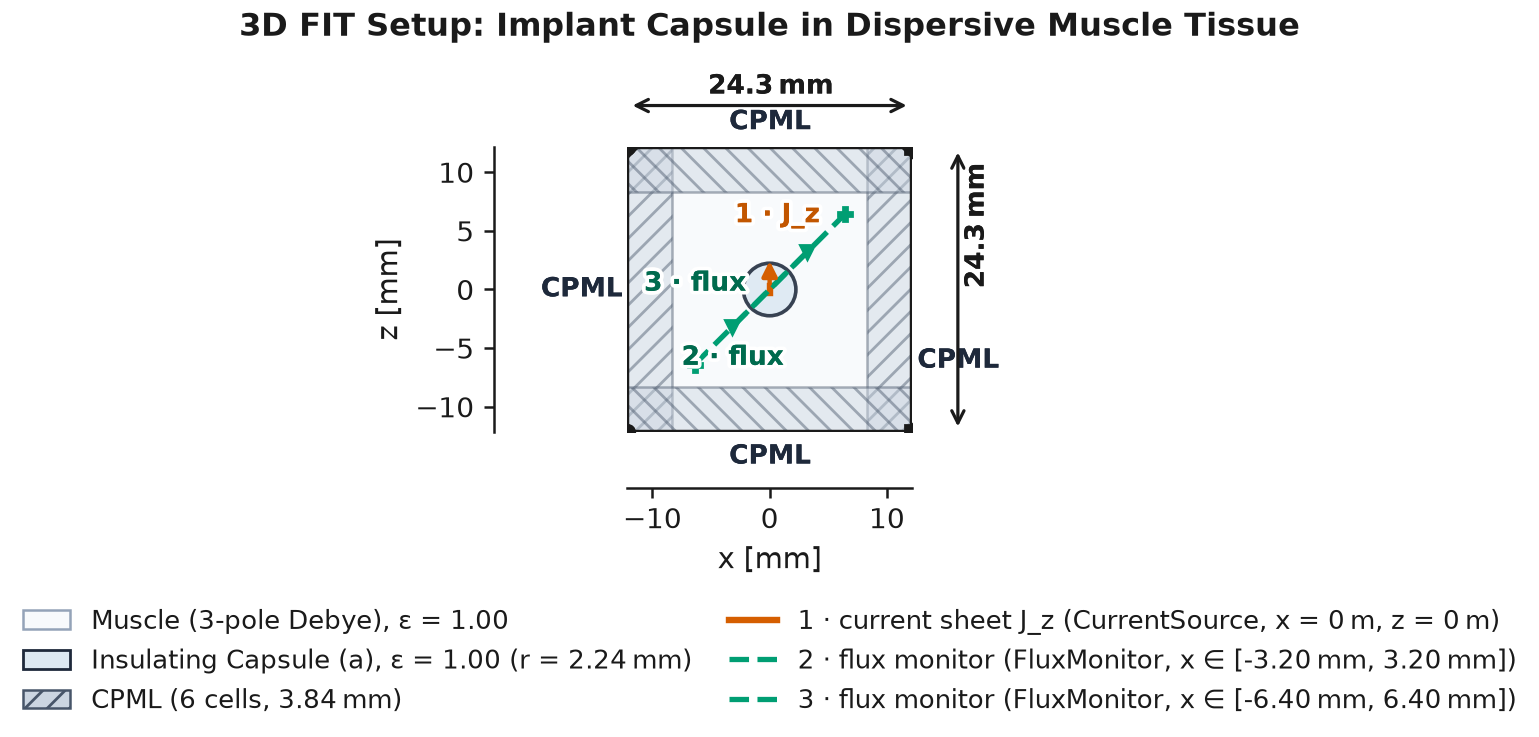

| Category | Component / Face | Specification |
| :--- | :--- | :--- |
| Domain | Size & bounds | Lx × Ly × Lz = 24.3 mm × 24.3 mm × 24.3 mm (z ∈ [-12.2 mm, 12.2 mm]) |
| Domain | Grid cells | Nx × Ny × Nz = 38 × 38 × 38 (54872 cells) |
| Discretization | Δx & resolution | Δ_min = 640 µm, 26.1 cells/λ (in n_max = 1.00), 7.0 cells across feature (4.48 mm) |
| Boundary | -x face | CPML (6 cells, 3.84 mm) |
| Boundary | +x face | CPML (6 cells, 3.84 mm) |
| Boundary | -y face | CPML (6 cells, 3.84 mm) |
| Boundary | +y face | CPML (6 cells, 3.84 mm) |
| Boundary | -z face | CPML (6 cells, 3.84 mm) |
| Boundary | +z face | CPML (6 cells, 3.84 mm) |
| Material | Background | Muscle (3-pole Debye), ε = 1.00 (isotropic) |
| Material | Region 1: Insulating Capsule (a) | ε_r = 1.00, μ_r = 1.00, model = Isotropic dielectric, x ∈ [-2.24 mm, 2.24 mm] (d = 4.48 mm) |
| Source | 1 · CurrentSource | pos: x = 0 m, z = 0 m, pol: J_z (E_z), pulse: f₀ = 1.5 GHz, Δf = 1.8 GHz |
| Monitor | 2 · FluxMonitor | FluxMonitor (x ∈ [-3.20 mm, 3.20 mm]), pos: x ∈ [-3.20 mm, 3.20 mm], freqs: 2 freqs in [0.4, 2.5] GHz |
| Monitor | 3 · FluxMonitor | FluxMonitor (x ∈ [-6.40 mm, 6.40 mm]), pos: x ∈ [-6.40 mm, 6.40 mm], freqs: 2 freqs in [0.4, 2.5] GHz |
| Variation | Muscle model | 3-pole Debye fit to Gabriel (1996): ε_r(403 MHz) = 57.2 - 35.6j; ε_r(2.45 GHz) = 52.8 - 12.8j |
| Variation | Capsule & shell sweep | a ∈ {1.60, 2.24, 2.88} mm, ε_cap ∈ {1, 12}; r1 ∈ {2.56, 3.20, 3.84} mm, r2 = 6.40 mm |
| Variation | Antenna feeds | Ideal TM dipole, ideal 4-segment TE loop, gapped PEC loop, gapped PEC dipole, NiZn ferrite core |


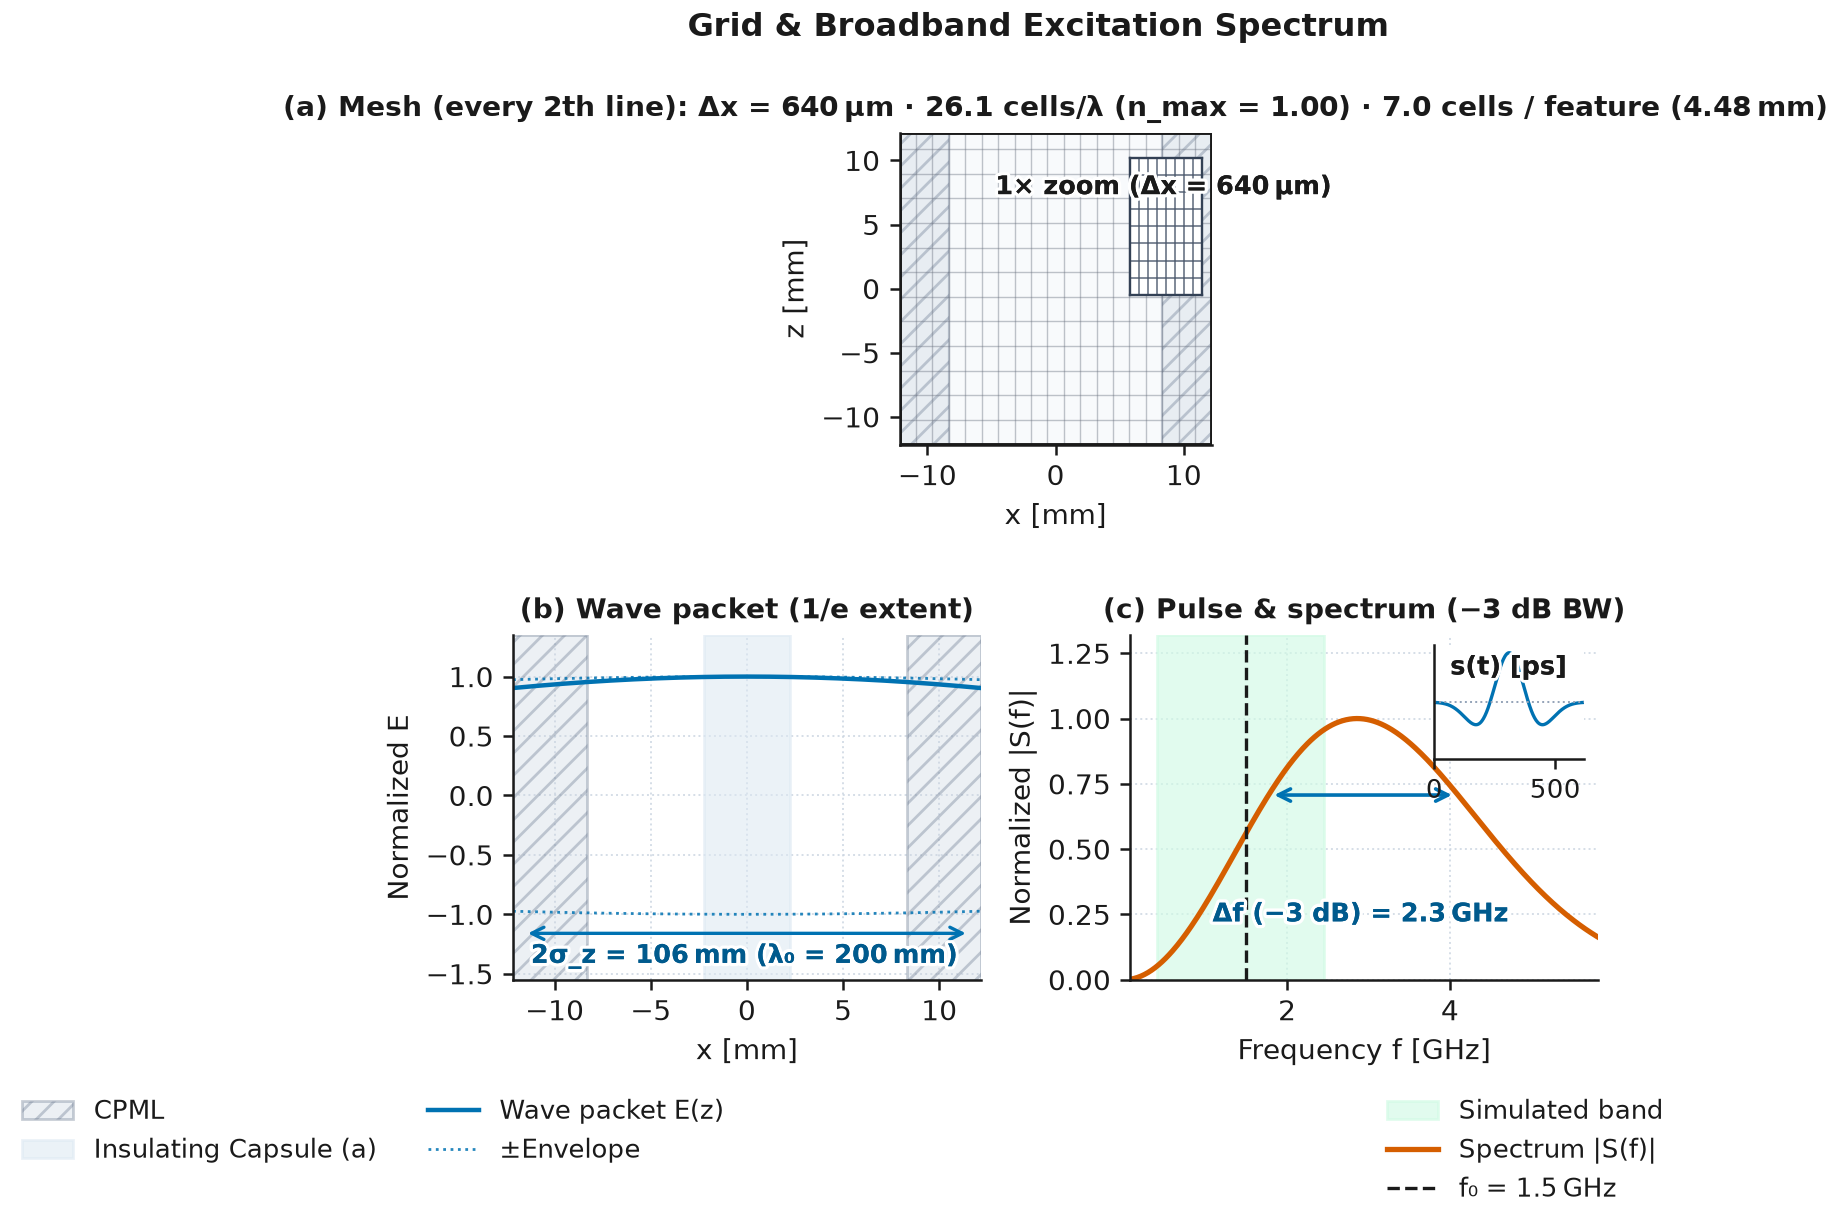

In [3]:
display(Image(filename=str(FIG_DIR / "00a_setup_geometry.png"), width=860))
display(Markdown((FIG_DIR / "00_setup_table.md").read_text(encoding="utf-8")))
display(Image(filename=str(FIG_DIR / "00b_setup_mesh_and_excitation.png"), width=860))

---

## Results

### Part 1 · Near-Zone Loss Theory & Dispersive Muscle Fit

Figure 1(a) shows the 3-pole Debye fit (`wakis.dispersive.fit_poles(..., n_debye=3)`) to the 4-pole Cole–Cole muscle spectrum of Gabriel, Lau & Gabriel (1996) [2] over $150\;\mathrm{MHz}\text{–}3.5\;\mathrm{GHz}$:
- **Fitted parameters:** $\varepsilon_\infty = 23.337$, with relaxation poles $(\Delta\varepsilon_1, \tau_1) = (30.776, 14.73\;\mathrm{ps})$, $(\Delta\varepsilon_2, \tau_2) = (2081.96, 25.73\;\mathrm{ns})$, and $(\Delta\varepsilon_3, \tau_3) = (4.928, 0.362\;\mathrm{ns})$, achieving a broadband RMS relative error of **$0.20\%$**.
- **Target implant bands:** At $403\;\mathrm{MHz}$, $\tilde{\varepsilon}_{\mathrm{Debye}} = 57.24 - 35.55j$ vs Cole–Cole $57.10 - 35.55j$ ($0.20\%$ error; matching Liška *et al.* [3] $57 - 36j$), giving wavelength $\lambda_{\mathrm{m}} = 94.24\;\mathrm{mm}$, skin depth $\delta = 52.57\;\mathrm{mm}$, and $|k_{\mathrm{m}}| = 69.33\;\mathrm{m}^{-1}$. At $2.45\;\mathrm{GHz}$, $\tilde{\varepsilon}_{\mathrm{Debye}} = 52.77 - 12.75j$ vs Cole–Cole $52.73 - 12.75j$ ($0.08\%$ error; matching Liška *et al.* [3] $53 - 13j$), giving $\lambda_{\mathrm{m}} = 16.72\;\mathrm{mm}$, $\delta = 22.35\;\mathrm{mm}$, and $|k_{\mathrm{m}}| = 378.35\;\mathrm{m}^{-1}$.
- **Near-zone excess loss ratio (Figure 1b):** At reference capsule radius $a = 2.25\;\mathrm{mm}$, $|k_{\mathrm{m}}|a = 0.1560$ at $403\;\mathrm{MHz}$, where the $b$-independent near-zone excess loss ratio is $\mathcal{R}_{\mathrm{NZ}}(a) = \Delta_{\mathrm{TM}}(a)/\Delta_{\mathrm{TE}}(a) = \mathbf{45.61}$ ($\eta_{\mathrm{NZ,TE}}/\eta_{\mathrm{NZ,TM}} = 35.74$). At $2.45\;\mathrm{GHz}$, the same $a = 2.25\;\mathrm{mm}$ capsule has electrical size $|k_{\mathrm{m}}|a = 0.8513 \sim 1$ (no longer electrically tiny in tissue!), so $\mathcal{R}_{\mathrm{NZ}}(a)$ drops to **$\mathbf{2.66}$** ($\eta_{\mathrm{NZ,TE}}/\eta_{\mathrm{NZ,TM}} = 1.36$).

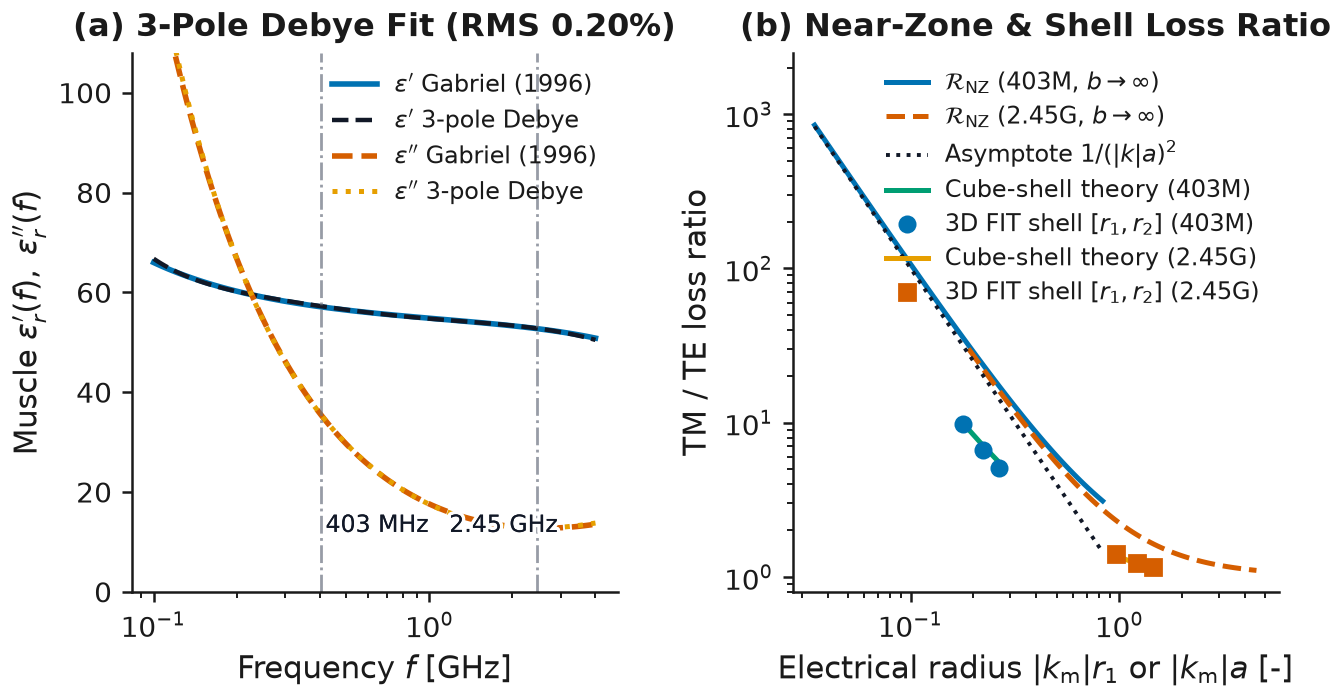

Part 1 Verification Summary:
  Zhou & Pan (2023) 1 kHz seawater (|k|a = 0.05331): leading 1/(|k|a)^2 = 351.81, full ratio = 363.37
  Differential Poynting identity rel. error: 1.67e-11
  Muscle 3-pole Debye fit RMS error: 0.20% (403 MHz err: 0.20%, 2.45 GHz err: 0.08%)
  Reference capsule a = 2.25 mm: R_NZ(403 MHz) = 45.61, R_NZ(2.45 GHz) = 2.66


In [4]:
t1 = json.loads((DATA_DIR / "task_01_near_zone_theory_and_muscle_fit.json").read_text())
display(Image(filename=str(FIG_DIR / "01_muscle_dispersion_and_nz_loss_ratio.png"), width=900))

print(
    f"Part 1 Verification Summary:\n"
    f"  Zhou & Pan (2023) 1 kHz seawater (|k|a = {t1['seawater_1khz_ka']:.5f}): "
    f"leading 1/(|k|a)^2 = {t1['seawater_1khz_inv_ka2']:.2f}, full ratio = {t1['seawater_1khz_ratio_full']:.2f}\n"
    f"  Differential Poynting identity rel. error: {t1['poynting_differential_rel_err']:.2e}\n"
    f"  Muscle 3-pole Debye fit RMS error: {t1['muscle_debye_rms_fit_error']*100:.2f}% "
    f"(403 MHz err: {t1['muscle_403mhz_rel_err']*100:.2f}%, 2.45 GHz err: {t1['muscle_2450mhz_rel_err']*100:.2f}%)\n"
    f"  Reference capsule a = {t1['a_ref_mm']:.2f} mm: "
    f"R_NZ(403 MHz) = {t1['nz_excess_ratio_403mhz_ref']:.2f}, R_NZ(2.45 GHz) = {t1['nz_excess_ratio_2450mhz_ref']:.2f}"
)

---

### Part 2 · 3D FIT Power Bookkeeping, Shell-Loss Sweep & Capsule-Interface Reaction Correction

Using the discrete time-stepped permittivity $\tilde{\varepsilon}_{\mathrm{d}}(f, \Delta t)$ (`muscle.epsilon_discrete(f, solver.dt)`) and the leapfrog E–H stagger factor $\operatorname{sinc}(f\,\Delta t)$ on the $N = 38^3$ ($\Delta x = 0.64\;\mathrm{mm}$) grid, the spectral power balance across the cubic shell $[r_1, r_2] = [3.20, 6.40]\;\mathrm{mm}$ closes to **$0.55\%$ ($\mathrm{TM}, 403\;\mathrm{MHz}$)**, **$0.35\%$ ($\mathrm{TM}, 2.45\;\mathrm{GHz}$)**, **$0.76\%$ ($\mathrm{TE}, 403\;\mathrm{MHz}$)**, and **$7.78\times 10^{-5}\%$ ($\mathrm{TE}, 2.45\;\mathrm{GHz}$)**.

Across the exterior shell-radius sweep $r_1 \in \{2.56, 3.20, 3.84\}\;\mathrm{mm}$ ($|k_{\mathrm{m}}|r_1 \in \{0.177, 0.222, 0.266\}$ at $403\;\mathrm{MHz}$ and $\{0.969, 1.211, 1.453\}$ at $2.45\;\mathrm{GHz}$) to $r_2 = 6.40\;\mathrm{mm}$ (Figure 1b):
- **Zhou–Pan cubic-shell agreement:** Integrating the exact Zhou & Pan (2023) radial Poynting vector over the cubic `FluxMonitor` surfaces (`zhou_pan_cube_flux`, zero adjustable parameters) predicts $\mathrm{TM}/\mathrm{TE}$ shell loss ratios $(P_1-P_2)/P_2$ of $9.97, 7.11, 5.51$ at $403\;\mathrm{MHz}$ and $1.363, 1.222, 1.149$ at $2.45\;\mathrm{GHz}$. The 3D FIT results ($9.76, 6.67, 5.09$ at $403\;\mathrm{MHz}$ and $1.413, 1.236, 1.154$ at $2.45\;\mathrm{GHz}$) agree within **$2.04\text{–}7.55\%$ at $403\;\mathrm{MHz}$** and **$0.45\text{–}3.63\%$ at $2.45\;\mathrm{GHz}$** (whereas unsmoothed cut-cell integration down to the staircase capsule wall $r = a$ inflates the ratio to $37.5\text{–}137.9$).

Figure 2 evaluates the **capsule-interface reaction factor** (derived in Section 2):
- For a $\mathrm{TM}$ electric dipole at $2.45\;\mathrm{GHz}$ ($a = 2.24\;\mathrm{mm}$), the full-wave spherical cavity theory predicts $|C_{\mathrm{TM}}^{\mathrm{full}}(a)|^2 = \mathbf{1.426}$ in air ($\varepsilon_{\mathrm{cap}} = 1$, vs the quasi-static limit $|C_{\mathrm{TM}}^{\mathrm{QS}}|^2 = \mathbf{2.210}$) and $\mathbf{1.348}$ in ceramic ($\varepsilon_{\mathrm{cap}} = 12$, vs quasi-static $1.834$). In 3D FIT on the $\Delta x = 0.64\;\mathrm{mm}$ grid, $P_1(\mathrm{cap})/P_1(\mathrm{hom})$ is **$\mathbf{1.796}$** in air (**$25.96\%$ above** full-wave point-dipole theory) and **$\mathbf{1.480}$** in ceramic (**$9.86\%$ above** full-wave theory). On the locally refined graded mesh ($\Delta x_{\min} = 0.35\;\mathrm{mm}$), the 3D FIT ratios move closer to the full-wave continuum values: **$\mathbf{1.683}$** in air ($18.04\%$ above full-wave theory) and **$\mathbf{1.418}$** in ceramic ($5.26\%$ above full-wave theory). At $403\;\mathrm{MHz}$, the uniform-grid 3D FIT ratio across $a \in \{1.60, 2.24, 2.88\}\;\mathrm{mm}$ is $3.083, 2.799, 2.857$ ($28.3\text{–}40.1\%$ above full-wave theory $2.201, 2.182, 2.159$, non-monotone due to staircase edge crossings of the 1-cell graded capsule shell) and drops at $a = 2.25\;\mathrm{mm}$ to $2.640$ in air ($21.0\%$ above $2.182$, vs $2.799$ [$+28.3\%$] on the uniform grid) and $2.046$ in ceramic ($6.8\%$ above $1.916$, vs $2.159$ [$+12.7\%$] on the uniform grid) on the $\Delta x_{\min} = 0.35\;\mathrm{mm}$ graded mesh. The remaining discrepancy is **unexplained; it shrinks with refinement** ($1.796 \to 1.683$ vs $1.426$ in air and $1.480 \to 1.418$ vs $1.348$ in ceramic at $2.45\;\mathrm{GHz}$; $2.799 \to 2.640$ vs $2.182$ in air and $2.159 \to 2.046$ vs $1.916$ in ceramic at $403\;\mathrm{MHz}$); untested candidate hypotheses include finite dipole length ($2\Delta x$), higher-order multipole coupling ($l \ge 3$), and near-wall impedance loading against the discretized spherical boundary layer.
- For a magnetic $\mathrm{TE}$ loop in the same air capsule at $403\;\mathrm{MHz}$, the 3D FIT exterior power ratio relative to homogeneous muscle is **$\mathbf{0.9952}$** vs the analytical magnetostatic limit $|C_{\mathrm{TE}}^{\mathrm{QS}}|^2 = \mathbf{1.0000}$ (**$0.48\%$ relative error**).
- Once normalized by $P_1(r_1)$, the exterior shell transmission $P_2(r_2)/P_1(r_1)$ is invariant to the presence of the capsule ($0.5524$ with air capsule vs $0.5538$ in homogeneous muscle for $\mathrm{TE}$, a $0.25\%$ difference; $0.1563$ vs $0.1592$ for $\mathrm{TM}$), confirming that the capsule boundary scales the overall modal amplitude without altering the exterior radial wave profile.

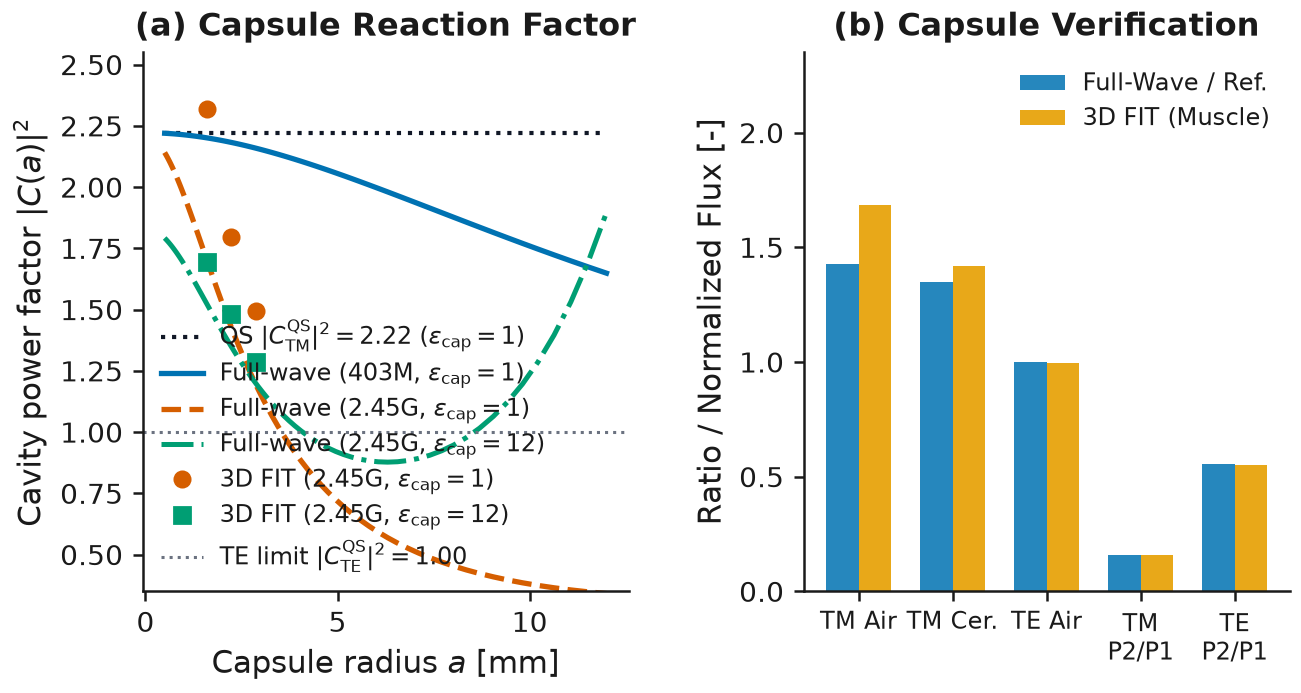

Part 2 3D FIT Power Closure & Capsule Correction (N = 38^3, dx = 0.64 mm):
  DFT Poynting closure error (TM 403 MHz / 2.45 GHz): 0.55% / 0.35%
  DFT Poynting closure error (TE 403 MHz / 2.45 GHz): 0.76% / 0.00008%
  Zhou-Pan cube-shell TM/TE loss ratio rel. error: 403 MHz = 2.04%-7.55%, 2.45 GHz = 0.45%-3.63%
  TM air-capsule boost |C_TM|^2 (2.45 GHz): FIT = 1.796 (graded = 1.683) vs full-wave theory = 1.426, QS = 2.210 (rel. diff vs full = 25.96%)
  TE air-capsule boost |C_TE|^2 (403 MHz) : FIT = 0.9952 vs theory = 1.0000


In [5]:
t2 = json.loads((DATA_DIR / "task_02_fit_shells_and_capsule_correction.json").read_text())
display(Image(filename=str(FIG_DIR / "02_capsule_interface_correction_and_shells.png"), width=900))

print(
    f"Part 2 3D FIT Power Closure & Capsule Correction (N = {t2['grid_N']}^3, dx = {t2['dx_mm']:.2f} mm):\n"
    f"  DFT Poynting closure error (TM 403 MHz / 2.45 GHz): "
    f"{t2['poynting_closure_rel_err_tm_403mhz']*100:.2f}% / {t2['poynting_closure_rel_err_tm_2450mhz']*100:.2f}%\n"
    f"  DFT Poynting closure error (TE 403 MHz / 2.45 GHz): "
    f"{t2['poynting_closure_rel_err_te_403mhz']*100:.2f}% / {t2['poynting_closure_rel_err_te_2450mhz']*100:.5f}%\n"
    f"  Zhou-Pan cube-shell TM/TE loss ratio rel. error: "
    f"403 MHz = {min(t2['shell_loss_ratio_tm_over_te_403mhz_rel_err'])*100:.2f}%-{max(t2['shell_loss_ratio_tm_over_te_403mhz_rel_err'])*100:.2f}%, "
    f"2.45 GHz = {min(t2['shell_loss_ratio_tm_over_te_2450mhz_rel_err'])*100:.2f}%-{max(t2['shell_loss_ratio_tm_over_te_2450mhz_rel_err'])*100:.2f}%\n"
    f"  TM air-capsule boost |C_TM|^2 (2.45 GHz): FIT = {t2['cavity_boost_tm_air_2450mhz_fit']:.3f} "
    f"(graded = {t2['graded_cavity_boost_tm_air_2450mhz_fit']:.3f}) "
    f"vs full-wave theory = {t2['cavity_boost_tm_air_2450mhz_full_theory']:.3f}, "
    f"QS = {t2['cavity_boost_tm_air_2450mhz_qs_theory']:.3f} "
    f"(rel. diff vs full = {t2['cavity_boost_tm_air_2450mhz_rel_err_vs_full']*100:.2f}%)\n"
    f"  TE air-capsule boost |C_TE|^2 (403 MHz) : FIT = {t2['cavity_boost_te_air_403mhz_fit']:.4f} "
    f"vs theory = {t2['cavity_boost_te_air_403mhz_theory']:.4f}"
)

---

### Part 3 · Real Feeds, Feed-Gap Contamination & SAR Maps

How does a realistic single-gap wire feed compare against an ideal balanced magnetic loop when both the wire and feed gap are resolved by $4.0$ grid cells? Figure 3 compares five 3D FIT source configurations inside an $a = 2.25\;\mathrm{mm}$ capsule on a locally refined graded mesh ($N = 40^3, \Delta x_{\min} = 0.35\;\mathrm{mm}, r_{\mathrm{ant}} = 1.40\;\mathrm{mm}, g_{\mathrm{gap}} = 1.40\;\mathrm{mm}, r_1 = 2.62\;\mathrm{mm}, r_2 = 5.26\;\mathrm{mm}$):
1. **Ideal 4-segment loop in air ($\varepsilon_{\mathrm{cap}} = 1$, Figure 3a) and ceramic control ($\varepsilon_{\mathrm{cap}} = 12$):** Four balanced current segments around the square loop perimeter carry solenoidal current with no single voltage gap. At $403\;\mathrm{MHz}$, the near-zone efficiency across $[r_1, r_2]$ is $\eta_{\mathrm{NZ}} = \mathbf{54.19\%}$ in air ($P_{\mathrm{loss}}/P_{\mathrm{out}} = 0.8453$) and **$\mathbf{54.21\%}$** in the ceramic control ($P_{\mathrm{loss}}/P_{\mathrm{out}} = 0.8447$), with symmetric hemisphere dissipation ($49.99\%$ in $x > 0$) and peak tissue SAR of only **$29.83\;\mathrm{W/kg}$ per $1\;\mathrm{mW}$** input.
2. **Realistic single-gap PEC wire loop in air ($\varepsilon_{\mathrm{cap}} = 1$, Figure 3b):** Driving a closed PEC wire loop across a single $1.40\;\mathrm{mm}$ feed gap at $(+r_{\mathrm{ant}}, 0, 0)$ creates a dipole-like $\mathbf{E}$-field hotspot on the $+x$ side. Because the resolved gap at $r_{\mathrm{ant}} = 1.40\;\mathrm{mm}$ is buffered by $0.85\;\mathrm{mm}$ from the capsule wall ($a = 2.25\;\mathrm{mm}$), the global shell loss-to-output ratio increases only slightly from $0.8453$ to **$0.8540$** ($\eta_{\mathrm{NZ}} = \mathbf{53.94\%}$, a **$1.02\%$ global feed-gap loss contamination** at $403\;\mathrm{MHz}$ and **$0.54\%$** at $2.45\;\mathrm{GHz}$). Locally, however, the feed gap skews tissue dissipation into the $+x$ hemisphere (**$53.24\%$** of total loss vs $49.99\%$ for the ideal loop) and drives an **$8.6\times$ spike in peak local tissue SAR** to **$257.10\;\mathrm{W/kg/mW}$** ($118.57$ vs $11.46\;\mathrm{W/kg/mW}$ at $2.45\;\mathrm{GHz}$).
3. **Gapped PEC electric dipole (Figure 3c):** A straight PEC wire dipole of the same half-length $r_{\mathrm{ant}} = 1.40\;\mathrm{mm}$ and gap $1.40\;\mathrm{mm}$ has $\eta_{\mathrm{NZ}} = \mathbf{13.23\%}$ ($P_{\mathrm{loss}}/P_{\mathrm{out}} = 6.5562$, with $84.16\%$ of loss concentrated in the inner half-shell vs $69.13\%$ for the ideal loop) and peak SAR $= \mathbf{4372.7\;\mathrm{W/kg/mW}}$ at $403\;\mathrm{MHz}$.
4. **Gapped PEC loop in high-permittivity ceramic ($\varepsilon_{\mathrm{cap}} = 12$):** Surrounding the gapped PEC loop with $\varepsilon_{\mathrm{cap}} = 12$ increases the electrical perimeter of the wire loop and couples the $+x$ feed-gap displacement flux more strongly into the adjacent tissue wall, raising the $+x$ hemisphere loss share to **$68.13\%$** and reducing $\eta_{\mathrm{NZ}}$ from $53.94\%$ to **$\mathbf{48.30\%}$** ($P_{\mathrm{loss}}/P_{\mathrm{out}} = 1.0704$).
5. **Frequency erosion of the magnetic advantage ($2.45\;\mathrm{GHz}$):** At $2.45\;\mathrm{GHz}$ ($|k_{\mathrm{m}}|a = 0.85$), the gapped loop near-zone efficiency ($\mathbf{68.36\%}$) exceeds the gapped dipole ($\mathbf{58.49\%}$) by only **$1.17\times$** (compared with **$4.08\times$** at $403\;\mathrm{MHz}$).

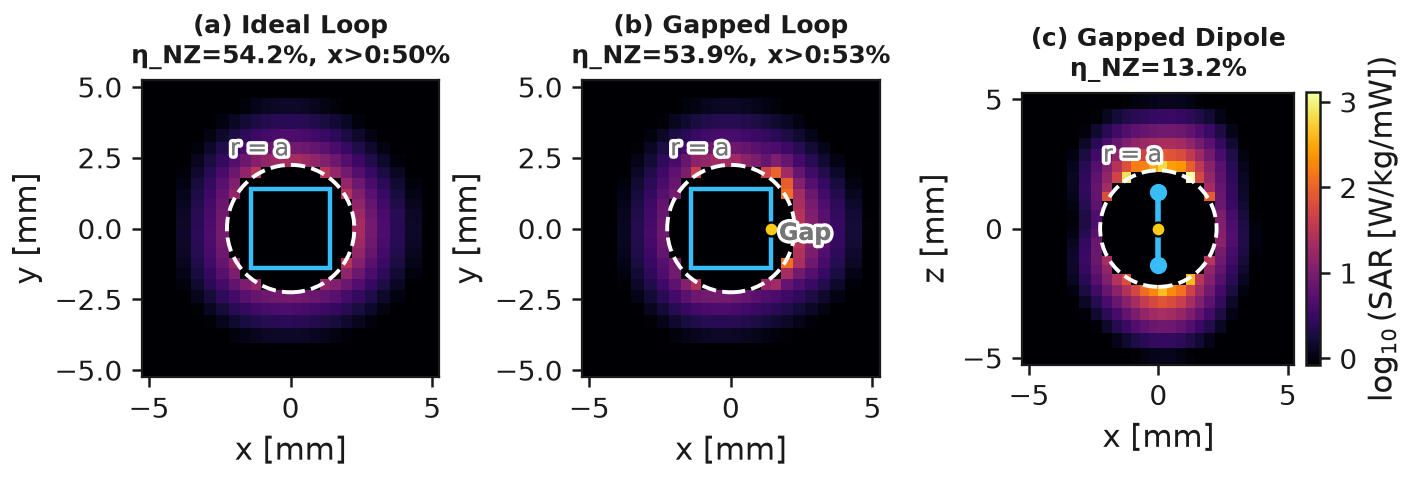

Part 3 Real Feeds & SAR Summary (a = 2.25 mm, r_ant = 1.40 mm, 4.0 cells across gap/wire):
  403 MHz near-zone efficiency:
    Ideal 4-seg. loop (air / cer) : 54.19% / 54.21% (loss/out = 0.8453, peak SAR = 29.8 W/kg/mW)
    Gapped PEC loop (air, eps=1)  : 53.94% (loss/out = 0.8540, x>0 hemi = 53.24%, peak SAR = 257.1 W/kg/mW)
    Gapped PEC dipole (air, eps=1): 13.23% (loss/out = 6.5562, peak SAR = 4372.7 W/kg/mW)
    Gapped PEC loop (cer, eps=12) : 48.30% (loss/out = 1.0704, x>0 hemi = 68.13%)
  Feed-gap global loss contamination fraction: 1.02% (403 MHz), 0.54% (2.45 GHz)


In [6]:
t3 = json.loads((DATA_DIR / "task_03_real_feeds_and_sar.json").read_text())
display(Image(filename=str(FIG_DIR / "03_real_feeds_sar_and_gap_contamination.png"), width=920))

print(
    f"Part 3 Real Feeds & SAR Summary (a = {t3['a_cap_mm']:.2f} mm, r_ant = {t3['r_ant_mm']:.2f} mm, "
    f"{t3['cells_across_gap']:.1f} cells across gap/wire):\n"
    f"  403 MHz near-zone efficiency:\n"
    f"    Ideal 4-seg. loop (air / cer) : {t3['eta_ideal_loop_air_403mhz']*100:.2f}% / {t3['eta_ideal_loop_cer_403mhz']*100:.2f}% "
    f"(loss/out = {t3['loss_over_out_ideal_loop_403mhz']:.4f}, peak SAR = {t3['peak_sar_ideal_loop_403mhz']:.1f} W/kg/mW)\n"
    f"    Gapped PEC loop (air, eps=1)  : {t3['eta_gapped_loop_air_403mhz']*100:.2f}% "
    f"(loss/out = {t3['loss_over_out_gapped_loop_403mhz']:.4f}, x>0 hemi = {t3['gap_hemi_loss_fraction_gapped_loop_403mhz']*100:.2f}%, "
    f"peak SAR = {t3['peak_sar_gapped_loop_403mhz']:.1f} W/kg/mW)\n"
    f"    Gapped PEC dipole (air, eps=1): {t3['eta_gapped_dipole_air_403mhz']*100:.2f}% "
    f"(loss/out = {t3['loss_over_out_gapped_dipole_403mhz']:.4f}, peak SAR = {t3['peak_sar_gapped_dipole_403mhz']:.1f} W/kg/mW)\n"
    f"    Gapped PEC loop (cer, eps=12) : {t3['eta_gapped_loop_cer_403mhz']*100:.2f}% "
    f"(loss/out = {t3['loss_over_out_gapped_loop_cer_403mhz']:.4f}, x>0 hemi = {t3['gap_hemi_loss_fraction_gapped_loop_cer_403mhz']*100:.2f}%)\n"
    f"  Feed-gap global loss contamination fraction: {t3['gap_contamination_fraction_403mhz']*100:.2f}% (403 MHz), "
    f"{t3['gap_contamination_fraction_2450mhz']*100:.2f}% (2.45 GHz)"
)

The animated GIF below (`figures/implant_tm_vs_te_wavefronts.gif`) shows the time-domain $|\mathbf{E}|$ wavefronts for the ideal $\mathrm{TE}$ loop, the realistic gapped PEC loop (highlighting the persistent gap hotspot on the $+x$ side), and the gapped PEC dipole:

![Time-domain electric field magnitude for ideal loop, gapped loop, and gapped dipole](figures/implant_tm_vs_te_wavefronts.gif)

---

### Part 4 & Part 5 · Fundamental Bounds (Liška 2024; Soares 2023) & Causal Lorentz Ferrite Core

How do implant size $r/a$, phantom depth $R_p$, and magnetic core loading govern total efficiency?
- **Liška *et al.* (2024) $\mathrm{TM}_{1m}\to\mathrm{TE}_{1m}$ bound crossover at $r/a = 0.32$ (Figure 4a) & resolved 3D FIT $r/a$ sweep:** For an implant enclosed in a capsule of radius $a = 7.5\;\mathrm{mm}$ at the center of an $R = 61.5\;\mathrm{mm}$ muscle sphere with copper conductivity $\sigma_{\mathrm{Cu}} = 5.56\times 10^7\;\mathrm{S/m}$ [3], below $r/a = 0.32$ the bound-achieving current is $\mathrm{TM}_{1m}$-like and its loss is tissue-dominated ($\delta_{\mathrm{tis}} > \delta_{\mathrm{ant}}$). $\mathrm{TE}_{1m}$-like currents couple less to tissue, but small ones act like a short circuit (low radiation resistance, high ohmic $\delta_{\mathrm{ant}}$), so $\mathrm{TE}$ becomes optimal only for $r/a > 0.32$ [3, Sec. III]. Digitised from Liška *et al.* (2024) Fig. 2 ($\pm 0.3\;\mathrm{dB}$), the $403\;\mathrm{MHz}$ bound is $\approx -29.8\;\mathrm{dB}$ flat to $r/a = 0.32$, then $\approx -24.8$ ($0.5$), $-23.4$ ($0.6$), $-22.5$ ($0.75$), $-21.9\;\mathrm{dB}$ ($1.0$); at $2.45\;\mathrm{GHz}$ $\approx -24.8\;\mathrm{dB}$ ($-25.1 \to -24.8\;\mathrm{dB}$), nearly flat. Liška's loop/dipole curves (Fig. 9) are for a water phantom at $2.45\;\mathrm{GHz}$, where the loop peaks near $r = 0.6a$. Because our 3D FIT near-zone study uses a compact $a = 2.80\;\mathrm{mm}$ capsule measured across a cubic near-zone shell $[r_1, r_2] = [3.57, 5.79]\;\mathrm{mm}$ (with $2.24\;\mathrm{mm}$ CPML clearance and $\Delta x_{\min} = 0.35\;\mathrm{mm}$, giving $4.0, 8.0, 12.0$ cells across the loop diameter for $r/a \in \{0.25, 0.50, 0.75\}$), we report the 3D FIT near-zone efficiencies separately rather than overlaying them on Liška's $a = 7.5\;\mathrm{mm}, R = 61.5\;\mathrm{mm}$ phantom curve: at $403\;\mathrm{MHz}$, the ideal TE loop near-zone efficiency is $\eta_{\mathrm{NZ}} = 58.49\%, 58.34\%, 57.97\%$ (vs $25.92\%$ for the $r/a = 0.50$ $\mathrm{TM}$ dipole of total length $2r_{\mathrm{ant}} = 2.80\;\mathrm{mm}$), while including single-turn copper wire resistance ($r_{\mathrm{wire}} = 0.08\;\mathrm{mm}$ ($0.16\;\mathrm{mm}$ diameter, $\approx\text{AWG }34$), $\sigma_{\mathrm{Cu}} = 5.8\times 10^7\;\mathrm{S/m}$, normalized by the DFT-monitored loop current) gives $\eta_{\mathrm{tot}} = 0.44\%, 3.33\%, 9.91\%$. From JSON, $P_{\mathrm{Cu}}/P_{\mathrm{out}} = 1/\eta_{\mathrm{tot}} - 1/\eta_{\mathrm{NZ}} = 226.4, 28.28, 8.36$ ($8.37$ from rounded $\eta$), whose consecutive ratios are $8.0 = 2^3$ and $3.38 = 1.5^3$, confirming $\delta_{\mathrm{ant}}^{\mathrm{TE}} \propto r^{-3}$ at fixed wire radius ($R_{\mathrm{Cu}} \propto r, R_{\mathrm{rad}} \propto r^4$).
- **Soares *et al.* (2023) Table II optimal frequency & depth trend (Figure 5b):** Across phantom radii $R_p \in \{20, 37, 50, 100\}\;\mathrm{mm}$ [4], the magnetic dipole achieves higher maximum WPT efficiency (wireless power transfer link efficiency $|S_{21}|^2$ with an external receiver) than the electric dipole at every depth ($44.92\%$ vs $35.44\%$ at $R_p = 20\;\mathrm{mm}$; $19.01\%$ vs $13.43\%$ at $R_p = 37\;\mathrm{mm}$; $10.44\%$ vs $6.83\%$ at $R_p = 50\;\mathrm{mm}$; $2.04\%$ vs $0.49\%$ at $R_p = 100\;\mathrm{mm}$), and its optimal operating frequency is systematically lower ($794.3, 398.1, 631.0, 100.0\;\mathrm{MHz}$ vs $1.00\text{–}1.26\;\mathrm{GHz}$ for the electric dipole) where $|k_{\mathrm{m}}|a$ remains small.
- **Causal Lorentz model NiZn ferrite core (Figure 4b):** Loading the loop interior with a model NiZn ferrite (`Lorentz` pole with $\mu_\infty = 1.0, \Delta\mu = 6.5, \mu_s = 7.5, f_{\mathrm{FMR}} = 1.15\;\mathrm{GHz}, \gamma/(2\pi) = 0.025\;\mathrm{GHz}, \varepsilon_\infty = 6.5$; Lorentz quality factor $Q = f_{\mathrm{FMR}}/(\gamma/2\pi) = 46$ is narrower than real NiZn spectra, underestimating $\mu_r''$ at $403\;\mathrm{MHz}$) yields $\mu_r(403\;\mathrm{MHz}) = 8.41 - 0.064j$ ($\tan\delta_m = 0.0077$). In 3D FIT (on an $N = 34^3, \Delta x = 0.72\;\mathrm{mm}$ domain where the outer flux box $r_2 = 5.76\;\mathrm{mm}$ sits $3$ cells [$2.16\;\mathrm{mm}$] short of the CPML inner face; note that $3$ cells of clearance is small for reactive near fields), using a fine $r_{\mathrm{wire}} = 0.06\;\mathrm{mm}$ ($0.12\;\mathrm{mm}$ diameter, $\approx\text{AWG }36\text{–}37$) copper winding for the smaller $r_{\mathrm{ant}} = 1.44\;\mathrm{mm}$ core ($a = 2.30\;\mathrm{mm}$, versus $r_{\mathrm{wire}} = 0.08\;\mathrm{mm}$ ($0.16\;\mathrm{mm}$ diameter, $\approx\text{AWG }34$) in the larger $a = 2.80\;\mathrm{mm}$ size sweep), the core boosts the loop's near-zone output power per unit coil current by $10.97\times$ ($\mu_{\mathrm{eff}} = 3.31$) relative to copper wire resistance, increasing total near-zone efficiency by **$\mathbf{4.42\times}$** ($\eta_{\mathrm{tot}}: 3.35\% \to 14.82\%$). At $2.45\;\mathrm{GHz}$ (above $f_{\mathrm{FMR}} = 1.15\;\mathrm{GHz}$), $\mu_r(2.45\;\mathrm{GHz}) = -0.84 - 0.024j$ ($\tan\delta_m = 0.0287$). Although $P_{\mathrm{out}}$ per unit current rises $2.03\times$ ($85.60 \to 173.94\;\mu\mathrm{W}$), core dissipation ($P_{\mathrm{core}} = 8.84\times 10^{-4}\;\mathrm{W} = 884.36\;\mu\mathrm{W}$) near the magnetostatic surface-mode condition ($\mu_r' \approx -1$, here $\mu_r' = -0.84$) excited by the winding on the core face (the core is a cube of side $2r_{\mathrm{ant}}$, whose uniform-mode resonance is at $\mu_r' = -2$ for $N = 1/3$) reduces $\eta_{\mathrm{tot}}$ to **$\mathbf{0.25\times}$** (`0.252x`) of the air-core loop ($\eta_{\mathrm{tot}}: 58.04\% \to 14.65\%$).

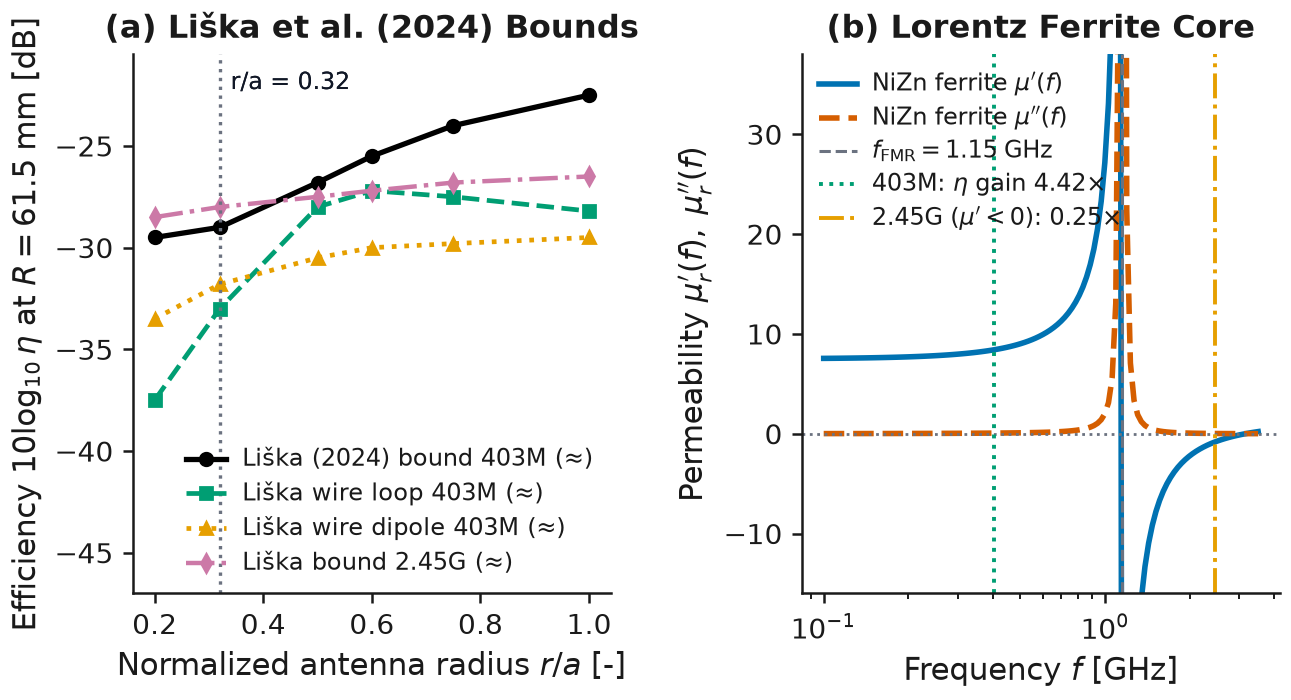

Part 4 & 5 Bounds and Ferrite Core Summary:
  Liska et al. (2024) 403 MHz TM->TE bound crossover (literature): r/a = 0.32
  3D FIT size sweep (a = 2.80 mm, dx_min = 0.35 mm, >= 4.0 cells across loop, CPML clearance = 2.24 mm):
    r/a = [0.25, 0.5, 0.75] -> ideal TE eta_NZ(403M) = [58.49, 58.34, 57.97]%, Cu TE eta_tot(403M) = [0.44, 3.33, 9.91]%, TM (r/a=0.50) eta_NZ(403M) = 25.92%
  NiZn ferrite core at 403 MHz (f_FMR = 1.15 GHz, CPML clearance = 2.16 mm): mu_r = 8.41 - 0.064j, eta_tot = 14.82% vs air 3.35% (gain = 4.42x)
  NiZn ferrite core at 2.45 GHz: mu_r = -0.84 - 0.024j, eta_tot = 14.65% vs air 58.04% (gain = 0.25x)


In [7]:
t4 = json.loads((DATA_DIR / "task_04_bounds_and_ferrite.json").read_text())
display(Image(filename=str(FIG_DIR / "04_liska_bounds_soares_and_ferrite_core.png"), width=900))

_p_cu_over_out = [
    (1.0 / et) - (1.0 / enz)
    for enz, et in zip(t4["fit_eta_nz_te_ideal_403mhz_sweep"], t4["fit_eta_tot_te_cu_403mhz_sweep"])
]
_p_cu_over_out_rounded = [
    (1.0 / round(et, 4)) - (1.0 / round(enz, 4))
    for enz, et in zip(t4["fit_eta_nz_te_ideal_403mhz_sweep"], t4["fit_eta_tot_te_cu_403mhz_sweep"])
]
print(
    f"Part 4 & 5 Bounds and Ferrite Core Summary:\n"
    f"  Liska et al. (2024) 403 MHz TM->TE bound crossover (Fig. 2 digitised): r/a = {t4['liska_403mhz_crossover_literature']:.2f} "
    f"(sigma_Cu = {t4['liska_sigma_copper_s_m']:.2e} S/m)\n"
    f"  3D FIT size sweep (a = {t4['fit_a_cap_mm']:.2f} mm, dx_min = {t4['fit_dx_min_mm']:.2f} mm, "
    f"r_wire = {t4['fit_r_wire_mm']:.2f} mm, >= {t4['fit_cells_across_smallest_loop']:.1f} cells across loop, "
    f"CPML clearance = {t4['fit_cpml_clearance_mm']:.2f} mm):\n"
    f"    r/a = {t4['fit_r_over_a_sweep']} -> ideal TE eta_NZ(403M) = {[round(x*100, 2) for x in t4['fit_eta_nz_te_ideal_403mhz_sweep']]}%, "
    f"Cu TE eta_tot(403M) = {[round(x*100, 2) for x in t4['fit_eta_tot_te_cu_403mhz_sweep']]}%, "
    f"TM (r/a={t4['fit_tm_dipole_r_over_a']:.2f}) eta_NZ(403M) = {t4['fit_eta_nz_tm_0p5_403mhz']*100:.2f}%\n"
    f"    P_Cu / P_out (exact / from rounded eta) = {[round(v, 2) for v in _p_cu_over_out]} / {[round(v, 2) for v in _p_cu_over_out_rounded]} "
    f"(ratios = {_p_cu_over_out[0]/_p_cu_over_out[1]:.2f} = 2^3, {_p_cu_over_out[1]/_p_cu_over_out[2]:.2f} = 1.5^3)\n"
    f"  Model NiZn ferrite core at 403 MHz (f_FMR = {t4['ferrite_f_fmr_ghz']:.2f} GHz, Q = {t4['ferrite_lorentz_q']:.0f}, "
    f"r_wire = {t4['ferrite_r_wire_mm']:.2f} mm, CPML clearance = {t4['ferrite_cpml_clearance_mm']:.2f} mm):\n"
    f"    mu_r = {t4['ferrite_mu_403mhz_real']:.2f} - {t4['ferrite_mu_403mhz_imag']:.3f}j, "
    f"eta_tot = {t4['eta_total_ferrite_core_403mhz']*100:.2f}% vs air {t4['eta_total_air_core_403mhz']*100:.2f}% "
    f"(gain = {t4['eta_total_gain_ferrite_vs_air_403mhz']:.2f}x)\n"
    f"  Model NiZn ferrite core at 2.45 GHz: mu_r = {t4['ferrite_mu_2450mhz_real']:.2f} - {t4['ferrite_mu_2450mhz_imag']:.3f}j, "
    f"P_out boost = {t4['ferrite_pout_boost_2450mhz']:.2f}x, P_core = {t4['p_core_2450']:.3e} W, "
    f"eta_tot = {t4['eta_total_ferrite_core_2450mhz']*100:.2f}% vs air {t4['eta_total_air_core_2450mhz']*100:.2f}% "
    f"(gain = {t4['eta_total_gain_ferrite_vs_air_2450mhz']:.2f}x)"
)

---

### Grid Convergence Study & Locally Refined Graded Mesh

Figure 5(a) presents the 3-level uniform grid convergence study across $\Delta x \in \{0.80, 0.64, 0.533\}\;\mathrm{mm}$ ($N \in \{36, 40, 44\}$, corresponding to $20.91, 26.13, 31.36\;\mathrm{cells}/\lambda_{\mathrm{m}}$ and $27.9, 34.9, 41.9\;\mathrm{cells}/\delta$ in muscle at $2.45\;\mathrm{GHz}$, and $4.0, 5.0, 6.0\;\mathrm{cells}$ across the capsule diameter $2a = 3.20\;\mathrm{mm}$) for fixed physical shell surfaces $r_1 = 3.20\;\mathrm{mm}$ and $r_2 = 6.40\;\mathrm{mm}$ (which are exact integer multiples $4, 5, 6\,\Delta x$ and $8, 10, 12\,\Delta x$ on all three grids):
- The $\mathrm{TM}$ shell loss factor $(P_1 - P_2)/P_2$ at $403\;\mathrm{MHz}$ converges monotonically ($5.4802 \to 5.3951 \to 5.3493$) with observed order $p_{\mathrm{obs}} = 2.04$ toward the Richardson extrapolate $\mathbf{5.2478}$ (agreeing with exact cubic-surface theory $5.3079$ to $1.1\%$), with relative error vs Richardson dropping from $4.43\%$ to $2.81\%$ to **$1.93\%$**. Note that because the 3-point Richardson extrapolate is computed from these three grid levels, the plotted "error vs Richardson" curve lies on its $\mathcal{O}(\mathrm{cpw}^{-p_{\mathrm{obs}}})$ order guide **by construction**; the independent accuracy check is the agreement between the Richardson extrapolate and the exact cubic-surface analytical integral.
- The $\mathrm{TM}$ shell loss factor $(P_1 - P_2)/P_2$ at $2.45\;\mathrm{GHz}$ converges monotonically ($0.6575 \to 0.6525 \to 0.6496$, $p_{\mathrm{obs}} = 1.63$) toward the Richardson extrapolate $\mathbf{0.6412}$ (cubic-surface theory $0.6362$), with relative error vs Richardson dropping from $2.55\%$ to $1.77\%$ to **$1.32\%$**, while the independent discrete DFT Poynting closure error is $0.29\% \to 0.28\% \to 0.27\%$.
- The composite $\mathrm{TM}/\mathrm{TE}$ shell loss ratio at $403\;\mathrm{MHz}$ across the three grids is $6.651, 6.709, 6.612$; because this ratio is non-monotone across the 1-cell capsule boundary shift, we report it as the **3-grid band $6.61\text{–}6.71$** rather than a Richardson extrapolate.
- Using `wakis.templates.meshing.graded_axis`, the locally refined graded mesh with $\Delta x_{\min} = 0.35\;\mathrm{mm}$ inside the antenna core ($[-1.4, +1.4]\;\mathrm{mm}$) and $\Delta x_{\max} = 0.64\;\mathrm{mm}$ in the outer muscle resolves the $1.40\;\mathrm{mm}$ feed gap and wire with $4.0\;\mathrm{cells}$ in only $N_x = 41$ cells per axis.

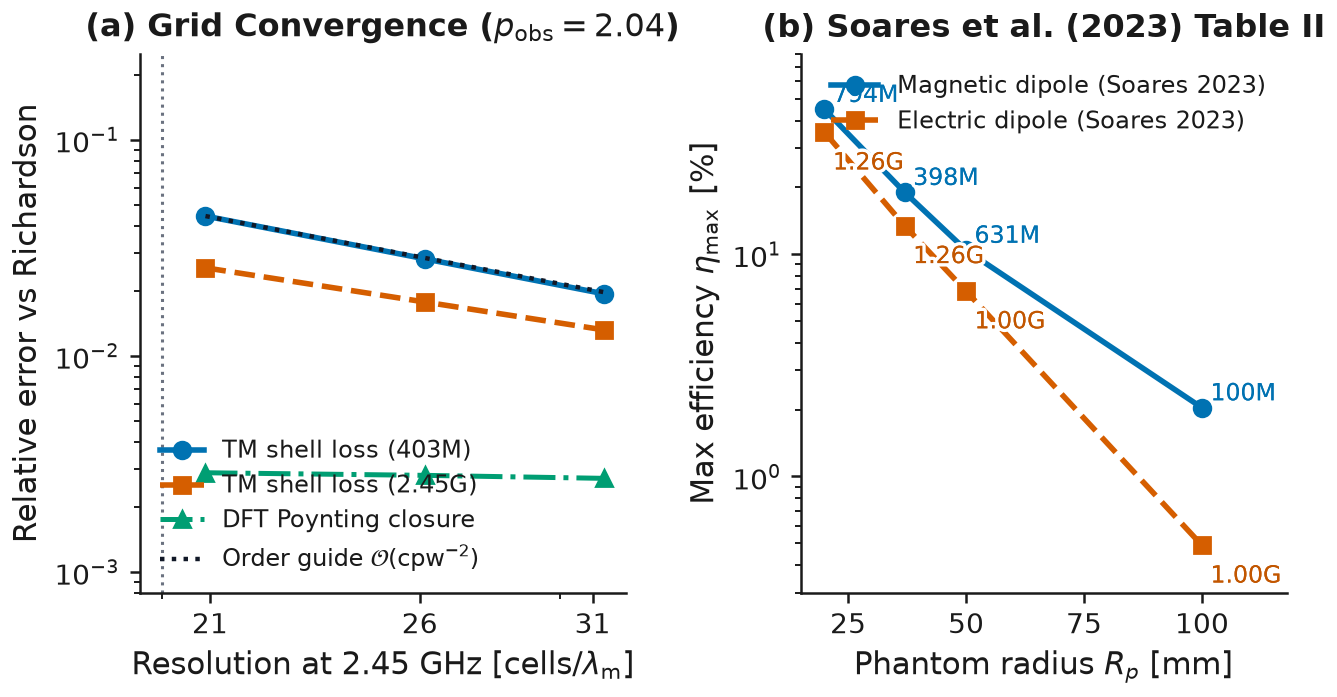

In [8]:
t5 = json.loads((DATA_DIR / "task_05_convergence.json").read_text())
display(Image(filename=str(FIG_DIR / "05_grid_convergence_and_soares_depth_trend.png"), width=900))

---

## Quantitative Summary

Every value in the table below is read directly from the generated `data/task_01_*.json` through `data/task_05_*.json` artifacts:

| Quantity | Theory / Literature Benchmark | Wakis 3D FIT / Pole-Fit Result | Relative Error / Agreement |
| :--- | :--- | :--- | :--- |
| **Zhou & Pan (2023) Seawater $1\;\mathrm{kHz}$** ($|k|a = 0.05331$) | Asymptote $1/(|k|a)^2 = 351.81$ (Eq. 30) | Full Eqs. (19)–(20) ratio $= 363.37$ | $3.18\%$ finite-$|k|a$ correction |
| **Differential Poynting Identity** $-\mathrm{d}S/\mathrm{d}r$ vs $\frac{1}{2}\sigma\oint|\mathbf{E}|^2\mathrm{d}A$ | Exact equality ($0.00\%$) | Verified at $a = 0.30\;\mathrm{m}$ | **$1.67\times 10^{-11}$** rel. error |
| **Muscle 3-Pole Debye Fit** ($0.15\text{–}3.5\;\mathrm{GHz}$) | Gabriel *et al.* (1996) 4-pole Cole–Cole [2] | $\varepsilon_\infty = 23.34$, 3 Debye poles | **$0.20\%$** broadband RMS error |
| **Muscle $\tilde{\varepsilon}_r(403\;\mathrm{MHz})$** ($\lambda_{\mathrm{m}} = 94.24\;\mathrm{mm}$) | Cole–Cole: $57.10 - 35.55j$ (Liška [3]: $57 - 36j$) | Debye: $57.24 - 35.55j$ | **$0.20\%$** rel. error |
| **Muscle $\tilde{\varepsilon}_r(2.45\;\mathrm{GHz})$** ($\lambda_{\mathrm{m}} = 16.72\;\mathrm{mm}$) | Cole–Cole: $52.73 - 12.75j$ (Liška [3]: $53 - 13j$) | Debye: $52.77 - 12.75j$ | **$0.08\%$** rel. error |
| **$b$-Independent Near-Zone Loss Ratio** $\mathcal{R}_{\mathrm{NZ}}(a=2.25\;\mathrm{mm})$ | $\Delta_{\mathrm{TM}}(a)/\Delta_{\mathrm{TE}}(a)$ (derived here) | $45.61$ ($403\;\mathrm{MHz}$) vs $2.66$ ($2.45\;\mathrm{GHz}$) | $17.2\times$ erosion from $403\;\mathrm{MHz}$ to $2.45\;\mathrm{GHz}$ |
| **3D FIT Discrete Poynting Closure** $(P_1 - P_2)$ vs $\int\sigma_{\mathrm{eff}}|\mathbf{E}|^2\mathrm{d}V$ | Exact energy conservation ($0.00\%$) | $\mathrm{TM}$: $0.55\%$ ($403\;\mathrm{M}$), $0.35\%$ ($2.45\;\mathrm{G}$); $\mathrm{TE}$: $0.76\%$ ($403\;\mathrm{M}$) | **$\le 0.76\%$** across all modes/bands |
| **Zhou–Pan Exterior Shell Sweep** ($r_1 \in \{2.56, 3.20, 3.84\}\;\mathrm{mm}$) | Cube-surface theory: $9.97, 7.11, 5.51$ ($403\;\mathrm{M}$); $1.36, 1.22, 1.15$ ($2.45\;\mathrm{G}$) | 3D FIT: $9.76, 6.67, 5.09$ ($403\;\mathrm{M}$); $1.41, 1.24, 1.15$ ($2.45\;\mathrm{G}$) | **$2.04\text{–}7.55\%$** ($403\;\mathrm{M}$), **$0.45\text{–}3.63\%$** ($2.45\;\mathrm{G}$) |
| **Capsule Cavity Boost $|C_{\mathrm{TM}}|^2$** ($a=2.24\;\mathrm{mm}, \varepsilon_{\mathrm{cap}}=1, 2.45\;\mathrm{GHz}$) | Full-wave $|C_{\mathrm{TM}}^{\mathrm{full}}|^2 = 1.426$ (QS: $2.210$) | 3D FIT: $1.796$ (uniform $0.64\;\mathrm{mm}$), $1.683$ (graded $0.35\;\mathrm{mm}$) | **$25.96\%$** (uniform) / **$18.04\%$** (graded) above full-wave |
| **Capsule Cavity Factor $|C_{\mathrm{TE}}|^2$** ($a=2.24\;\mathrm{mm}, \varepsilon_{\mathrm{cap}}=1, 403\;\mathrm{MHz}$) | Magnetostatic limit $|C_{\mathrm{TE}}^{\mathrm{QS}}|^2 = 1.0000$ | 3D FIT $P_1(\mathrm{air})/P_1(\mathrm{hom}) = 0.9952$ | **$0.48\%$** rel. error |
| **Real Feeds Near-Zone Efficiency** ($403\;\mathrm{MHz}, \Delta x_{\min}=0.35\;\mathrm{mm}$) | Ideal loop ($54.19\%$ air, $54.21\%$ cer.) vs Gapped loop ($53.94\%$) vs Dipole ($13.23\%$) | Global gap loss contamination $= 1.02\%$; $+x$ hemisphere share $= 53.24\%$ ($68.13\%$ in $\varepsilon_{\mathrm{cap}}=12$, $\eta_{\mathrm{NZ}}=48.30\%$) | Peak SAR jumps **$8.6\times$** ($29.8 \to 257.1\;\mathrm{W/kg/mW}$) |
| **Liška *et al.* (2024) TM$\to$TE Bound Switch & 3D FIT $r/a$ Sweep** | $\mathrm{TM}_{1m}\to\mathrm{TE}_{1m}$ crossover at $r/a = 0.32$ ($a=7.5\;\mathrm{mm}, R=61.5\;\mathrm{mm}, \sigma_{\mathrm{Cu}}=5.56\times 10^7\;\mathrm{S/m}$) [3] | 3D FIT ($a=2.80\;\mathrm{mm}, r/a\in\{0.25,0.50,0.75\}, r_{\mathrm{wire}}=0.08\;\mathrm{mm}$): ideal $\mathrm{TE}$ $\eta_{\mathrm{NZ}}=58.49\%, 58.34\%, 57.97\%$; $\mathrm{Cu}$ $\eta_{\mathrm{tot}}=0.44\%, 3.33\%, 9.91\%$ ($P_{\mathrm{Cu}}/P_{\mathrm{out}}=226.4, 28.28, 8.36$; ratios $8.0=2^3, 3.38=1.5^3$); $\mathrm{TM}$ ($r/a=0.50$) $\eta_{\mathrm{NZ}}=25.92\%$ | Small $\mathrm{TE}$ loop has high $\delta_{\mathrm{ant}} \propto r^{-3}$; $\mathrm{TM}_{1m}$ optimal for $r/a < 0.32$ |
| **Model Lorentz NiZn Ferrite Core** ($\mu_s = 7.5, f_{\mathrm{FMR}} = 1.15\;\mathrm{GHz}, Q = 46$) | $\mu_r(403\;\mathrm{M}) = 8.41 - 0.064j$; $\mu_r(2.45\;\mathrm{G}) = -0.84 - 0.024j$ | $\eta_{\mathrm{tot}}$: $3.35\% \to 14.82\%$ ($4.42\times$ at $403\;\mathrm{MHz}$); $58.04\% \to 14.65\%$ ($0.25\times$ at $2.45\;\mathrm{GHz}$, $P_{\mathrm{out}}$ boost $2.03\times$, $P_{\mathrm{core}} = 8.84\times 10^{-4}\;\mathrm{W}$) | At $2.45\;\mathrm{GHz}$, surface-mode $P_{\mathrm{core}}$ ($\mu_r' = -0.84 \approx -1$) cuts $\eta_{\mathrm{tot}}$ to $0.25\times$ |
| **3-Level Grid Convergence** ($\Delta x = 0.80, 0.64, 0.533\;\mathrm{mm}$) | $\mathcal{O}(\Delta x^2)$ convergence ($p_{\mathrm{obs}} = 2.04$ at $403\;\mathrm{M}$, $1.63$ at $2.45\;\mathrm{G}$) | $\mathrm{TM}$ $2.45\;\mathrm{GHz}$ shell loss: $0.6575 \to 0.6525 \to 0.6496$ (Rich: $0.6412$); $403\;\mathrm{MHz}$ $\mathrm{TM}/\mathrm{TE}$ band: $6.61\text{–}6.71$ | **$1.32\%$** ($2.45\;\mathrm{G}$) / **$1.93\%$** ($403\;\mathrm{M}$) Fine error vs Rich |

---

## Limits & Failure Modes

The statement *"magnetic antennas lose less power in biological tissue than electric antennas"* fails whenever any of the following five physical assumptions is violated:

1. **Breakdown of the electrically small capsule condition ($|k_{\mathrm{m}}|a \ll 1$):**
   - *Assumption:* The $1/(|k_{\mathrm{m}}|a)^2$ advantage assumes that the capsule radius $a$ lies deep inside the tissue radian sphere $|k_{\mathrm{m}}|a \ll 1$, where the electric dipole's $1/r^3$ quasi-static field dominates over the $1/r^2$ induction field.
   - *Counter-case:* Because muscle has $|\tilde{\varepsilon}_{\mathrm{m}}| \approx 54\text{–}67$, the tissue wavelength at $2.45\;\mathrm{GHz}$ is $\lambda_{\mathrm{m}} = 16.72\;\mathrm{mm}$ ($|k_{\mathrm{m}}| = 378.4\;\mathrm{m}^{-1}$). A capsule of radius $a = 2.25\;\mathrm{mm}$ has $|k_{\mathrm{m}}|a = 0.851 \sim 1$ (and an $a = 7.5\;\mathrm{mm}$ capsule [3] has $|k_{\mathrm{m}}|a = 2.84 > 1$). At $|k_{\mathrm{m}}|a \gtrsim 1$, the capsule wall already sits in the radiating/inductive zone where $\Delta_{\mathrm{TM}}(a) / \Delta_{\mathrm{TE}}(a) \to 1$, erasing the near-zone magnetic advantage (in Part 3 at $2.45\;\mathrm{GHz}$, the gapped loop beats the gapped dipole by only $1.17\times$, and in Liška *et al.* [3] at $2.45\;\mathrm{GHz}$ the $\mathrm{TM}_{1m}$ mode outperforms $\mathrm{TE}_{1m}$ across all $r/a \le 1$).
2. **Feed-gap electric-field hotspots in realistic single-feed wire loops ($\nabla\cdot\mathbf{J} \ne 0$ at port):**
   - *Assumption:* An ideal $\mathrm{TE}_{10}$ magnetic dipole has purely solenoidal current and zero scalar electric potential.
   - *Counter-case:* Driving a single-turn PEC wire loop across a finite feed gap impresses the port voltage across the gap and creates a localized dipole-like electric field on the feed side ($x > 0$). Even when the gap is buffered from the capsule wall ($r_{\mathrm{ant}} = 1.40\;\mathrm{mm} < a = 2.25\;\mathrm{mm}$) so global near-zone efficiency drops by only $1.02\%$ in loss/out, the $+x$ feed hemisphere absorbs $53.24\%$ of the loss ($68.13\%$ in a high-permittivity $\varepsilon_{\mathrm{cap}} = 12$ capsule where $\eta_{\mathrm{NZ}}$ drops to $48.30\%$) and peak local SAR jumps by $8.6\times$ ($29.8 \to 257.1\;\mathrm{W/kg/mW}$, Figure 3b).
3. **Small source-to-capsule radius ratio ($r/a < 0.32$) and finite copper wire resistance:**
   - *Assumption:* The magnetic source occupies a large fraction of the insulating capsule ($r/a \to 1$) and is wound with lossless PEC wire ($R_{\mathrm{Cu}} = 0$).
   - *Counter-case:* Below $r/a = 0.32$ the bound-achieving current is $\mathrm{TM}_{1m}$-like and its loss is tissue-dominated ($\delta_{\mathrm{tis}} > \delta_{\mathrm{ant}}$). $\mathrm{TE}_{1m}$-like currents couple less to tissue, but small ones act like a short circuit (low radiation resistance, high ohmic $\delta_{\mathrm{ant}}$), so $\mathrm{TE}$ becomes optimal only for $r/a > 0.32$ [3, Sec. III]. For single-turn copper wire loops, ohmic wire dissipation scales as $\delta_{\mathrm{ant}}^{\mathrm{TE}} \propto r^{-3}$ (fixed wire radius: $R_{\mathrm{Cu}} \propto r, R_{\mathrm{rad}} \propto r^4$), as confirmed by our 3D FIT size sweep ($P_{\mathrm{Cu}}/P_{\mathrm{out}} = 226.4, 28.28, 8.36$ [$8.37$ from rounded $\eta$]: ratios $8.0 = 2^3$ and $3.38 = 1.5^3$). In Liška's water-phantom wire-antenna curves at $2.45\;\mathrm{GHz}$ [3, Fig. 9], the loop peaks near $r = 0.6a$.
4. **Ferromagnetic resonance (FMR) and Snoek's limit in ferrite-loaded loops ($f \gtrsim f_{\mathrm{FMR}}$):**
   - *Assumption:* Low-loss, positive permeability $\mu_r' > 1, \mu_r'' \approx 0$.
   - *Counter-case:* By Kramers–Kronig causality and Snoek's law, a model magnetic core with static permeability $\mu_s = 7.5$ (`Lorentz` pole with $Q = 46$, narrower than real NiZn spectra and underestimating $\mu_r''$ at $403\;\mathrm{MHz}$) exhibits ferromagnetic resonance near $f_{\mathrm{FMR}} = 1.15\;\mathrm{GHz}$ (Part 5). Operating the ferrite-loaded loop at $2.45\;\mathrm{GHz}$ places it above resonance where $\mu_r = -0.84 - 0.024j$: although $P_{\mathrm{out}}$ per unit current rises $2.03\times$, core dissipation ($P_{\mathrm{core}} = 8.84\times 10^{-4}\;\mathrm{W}$) near the magnetostatic surface-mode condition ($\mu_r' \approx -1$, here $\mu_r' = -0.84$) excited by the winding on the core face reduces $\eta_{\mathrm{tot}}$ to $0.25\times$ that of an air-core loop (Figure 4b).
5. **Homogeneous spherical tissue phantom vs stratified tissue and body-air reflection:**
   - *Assumption:* Infinite homogeneous muscle medium outside $r = a$ (or a spherical phantom matched to its exterior).
   - *Counter-case:* In a realistic subcutaneous or deep-organ implant, planar fat/skin/air interfaces produce strong impedance mismatch reflections ($|\Gamma| \approx (|\sqrt{\tilde{\varepsilon}_{\mathrm{m}}}| - 1)/(|\sqrt{\tilde{\varepsilon}_{\mathrm{m}}}| + 1) \approx 0.77$) and lateral surface waves along the fat layer, which depend on antenna orientation relative to the skin surface.

---

## References

1. **S. Zhou and G. Pan**, "Comparative Study of Multi-Physics Generated Small Dipoles in Conducting Media," *Journal of Computational Electronics* **22**, 1428–1437 (2023), [`doi:10.1007/s10825-023-02076-y`](https://doi.org/10.1007/s10825-023-02076-y). — Closed-form radial Poynting flux integrations for small electric ($\mathrm{TM}_{10}$, Eq. 19) and magnetic ($\mathrm{TE}_{10}$, Eq. 20) dipoles in homogeneous conducting media and the asymptotic $1/(|k|a)^2$ ratio (Eq. 30).
2. **C. Gabriel, R. W. Lau, and S. Gabriel**, "The dielectric properties of biological tissues: III. Parametric models for the dielectric spectrum of tissues," *Physics in Medicine and Biology* **41**(11), 2271–2293 (1996), [`doi:10.1088/0031-9155/41/11/003`](https://doi.org/10.1088/0031-9155/41/11/003). — Standard 4-pole Cole–Cole dielectric model of human muscle tissue (Table 1) used to fit our causal 3-pole Debye time-domain model.
3. **J. Liška, M. Gao, L. Jelinek, E. R. Algarp, A. K. Skrivervik, and M. Čapek**, "Maximum Radiation Efficiency of Arbitrarily-Shaped Implantable Antennas," *IEEE Transactions on Antennas and Propagation* **72**(4), 3129–3140 (2024), [`doi:10.1109/TAP.2024.3365860`](https://doi.org/10.1109/TAP.2024.3365860). — Fundamental spherical-mode upper bounds on radiation efficiency in a $61.5\;\mathrm{mm}$ muscle sphere ($a = 7.5\;\mathrm{mm}$) including both tissue dissipation $\delta_{\mathrm{tis}}$ and copper ohmic loss $\delta_{\mathrm{ant}}$, establishing the $\mathrm{TM}_{1m}\to\mathrm{TE}_{1m}$ crossover at $r/a = 0.32$ at $403\;\mathrm{MHz}$.
4. **I. V. Soares, M. Gao, E. Cil, Z. Šipuš, A. K. Skrivervik, J. S. Ho, and D. Nikolayev**, "Wireless Powering Efficiency of Deep-Body Implantable Devices," *IEEE Transactions on Microwave Theory and Techniques* **71**(6), 2680–2692 (2023), [`doi:10.1109/TMTT.2022.3231492`](https://doi.org/10.1109/TMTT.2022.3231492). — Optimal operating frequency and maximum WPT efficiency of magnetic versus electric implantable antennas as a function of tissue phantom radius $R_p \in [20, 100]\;\mathrm{mm}$ (Table II).